### Time Series Analysis of Network Utilization for Distributed Scientific Workflows
#### Yingxin Deng
#### 2026/09/21

### This week's task: Early-period evaluation of the Week 2 Structured TCN

1. Use 28 daily observations to predict the next day.
2. Keep three residual blocks, two convolutions per block, 32 channels, kernel size 3, dilations [1, 2, 4], and dropout 0.1. The receptive field is 29 days.
3. Restrict this experiment to the first regime, 2020-05-31 through 2021-09-30. Split daily rows chronologically into 70% training, 15% validation, and 15% testing before building windows, following Week 2. No target crosses into the second regime.
4. Fit input and log-target scalers on the training period only.
5. Retain the Week 2 structured loss for both training and validation. Select the lowest validation structured loss checkpoint; RMSE is used only for final evaluation.
6. Evaluate the selected checkpoint directly, without merging validation into training or updating weights during testing.
7. Report six original-unit RMSE values and inspect actual versus predicted curves, especially miss count and miss size.

This historical comparison investigates prediction variability; it does not by itself establish that a change point caused the Week 2 errors.

## 1. Imports and fixed settings

In [8]:
from pathlib import Path
import copy
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
LOOKBACK, HORIZON = 28, 1
TEST_END = pd.Timestamp('2021-09-30')
TRAIN_FRACTION, VALIDATION_FRACTION = 0.70, 0.15
FEATURE_NAMES = ['access_count', 'access_size', 'hit_count', 'hit_size', 'miss_count', 'miss_size']
PRIMARY_SELECTION_VARIABLE = 'hit_size'
PRIMARY_SELECTION_INDEX = FEATURE_NAMES.index(PRIMARY_SELECTION_VARIABLE)
CHANNELS, KERNEL_SIZE, DROPOUT = (32, 32, 32), 3, 0.1
MAX_EPOCHS, PATIENCE, BATCH_SIZE = 60, 10, 32
LEARNING_RATE = 1e-3
SELECTION_TARGET = 'validation_structured_loss'

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch: {torch.__version__}; device: {device}')

PyTorch: 2.2.2; device: cpu


## 2. Load data and verify chronological boundaries

Size variables are converted from bytes to TB once, immediately after loading. Data after the early test period are excluded.

In [9]:
data_dirs = [
    Path('../xcache-ts-df'), Path('../xcache-ts/pickled_data/df'),
    Path('xcache-ts-df'), Path('xcache-ts/pickled_data/df'),
]
data_file = next((p / 'socal-2006-2403-daily-ml' for p in data_dirs
                  if (p / 'socal-2006-2403-daily-ml').is_file()), None)
if data_file is None:
    raise FileNotFoundError('Cannot find the SoCal daily data.')
df = pd.read_pickle(data_file).loc['2020-05-31':TEST_END, FEATURE_NAMES].copy()
df[['access_size', 'hit_size', 'miss_size']] /= 1000 ** 4
assert df.index.is_unique and df.index.is_monotonic_increasing
assert df.index.equals(pd.date_range('2020-05-31', TEST_END, freq='D'))
assert np.isfinite(df.to_numpy()).all() and (df.to_numpy() >= 0).all()
for suffix in ['count', 'size']:
    np.testing.assert_allclose(
        df['access_' + suffix], df['hit_' + suffix] + df['miss_' + suffix],
        rtol=1e-5, atol=1e-6,
    )
print(f'Data: {df.index.min().date()} to {df.index.max().date()}, {len(df)} days')
display(df.head())

# Determine boundaries from daily observations before constructing windows.
train_end_position = int(len(df) * TRAIN_FRACTION)
validation_end_position = int(len(df) * (TRAIN_FRACTION + VALIDATION_FRACTION))
TRAIN_END = df.index[train_end_position - 1]
VALIDATION_END = df.index[validation_end_position - 1]
print('Train:', df.index[0].date(), 'to', TRAIN_END.date())
print('Validation:', df.index[train_end_position].date(), 'to', VALIDATION_END.date())
print('Test:', df.index[validation_end_position].date(), 'to', TEST_END.date())

Data: 2020-05-31 to 2021-09-30, 488 days


,access_count,access_size,hit_count,hit_size,miss_count,miss_size
data_start_time_datetime,,,,,,
2020-05-31,9615,7.247672,5648,4.306678,3967,2.940994
2020-06-01,37391,23.700100,22909,14.073827,14482,9.626272
2020-06-02,61088,34.787786,25539,11.936270,35549,22.851516
2020-06-03,35953,26.438742,23689,18.058082,12264,8.380659
2020-06-04,44218,40.089986,31600,26.688669,12618,13.401317


Train: 2020-05-31 to 2021-05-06
Validation: 2021-05-07 to 2021-07-18
Test: 2021-07-19 to 2021-09-30


## 3. Structured targets, training-only scaling, and windows

Inputs contain log1p access count, log1p access size, and two hit ratios. Ratios remain unscaled as targets. Split by target date; an input window may use earlier observations across a split boundary. No input includes its target day.

In [10]:
count_ratio = np.divide(df['hit_count'], df['access_count'],
                        out=np.zeros(len(df)), where=df['access_count'] > 0)
size_ratio = np.divide(df['hit_size'], df['access_size'],
                       out=np.zeros(len(df)), where=df['access_size'] > 0)
structured_values = np.column_stack([
    np.log1p(df['access_count']), np.log1p(df['access_size']), count_ratio, size_ratio,
]).astype(np.float32)
assert ((structured_values[:, 2:] >= 0) & (structured_values[:, 2:] <= 1)).all()
train_rows = df.index <= TRAIN_END
input_scaler = StandardScaler().fit(structured_values[train_rows])
log_target_scaler = StandardScaler().fit(structured_values[train_rows, :2])
inputs = input_scaler.transform(structured_values).astype(np.float32)
targets = np.column_stack([
    log_target_scaler.transform(structured_values[:, :2]), structured_values[:, 2:],
]).astype(np.float32)

positions = np.arange(LOOKBACK, len(df))
X = np.asarray([inputs[p - LOOKBACK:p] for p in positions], dtype=np.float32)
y = targets[positions, None, :]
dates = df.index[positions]
masks = {
    'Train': dates <= TRAIN_END,
    'Validation': (dates > TRAIN_END) & (dates <= VALIDATION_END),
    'Test': (dates > VALIDATION_END) & (dates <= TEST_END),
}
split_rows = []
for name, mask in masks.items():
    split_rows.append({'Split': name, 'First target': dates[mask].min().date(),
                       'Last target': dates[mask].max().date(), 'Samples': int(mask.sum())})
display(pd.DataFrame(split_rows))
assert [int(masks[k].sum()) for k in masks] == [train_end_position - LOOKBACK, validation_end_position - train_end_position, len(df) - validation_end_position]
print('Scaler fitting days:', int(train_rows.sum()))

,Split,First target,Last target,Samples
0,Train,2020-06-28,2021-05-06,313
1,Validation,2021-05-07,2021-07-18,73
2,Test,2021-07-19,2021-09-30,74


Scaler fitting days: 341


## 4. Week 2 Structured TCN

The architecture and structured loss are retained. Sigmoid bounds hit ratios; reconstruction clips access at zero and derives hit and miss from access and ratios.

In [11]:
class Chomp1d(nn.Module):
    def __init__(self, size):
        super().__init__()
        self.size = size

    def forward(self, x):
        return x[:, :, :-self.size].contiguous() if self.size > 0 else x

class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation, dropout):
        super().__init__()
        padding = (kernel_size - 1) * dilation
        self.net = nn.Sequential(
            nn.Conv1d(in_channels, out_channels, kernel_size, padding=padding, dilation=dilation),
            Chomp1d(padding), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(out_channels, out_channels, kernel_size, padding=padding, dilation=dilation),
            Chomp1d(padding), nn.ReLU(), nn.Dropout(dropout)
        )
        self.residual = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def forward(self, x):
        return torch.relu(self.net(x) + self.residual(x))

class TCNForecaster(nn.Module):
    def __init__(self, input_size, output_size, horizon, channels=(32, 32, 32), kernel_size=3, dropout=0.1):
        super().__init__()
        blocks, in_channels = [], input_size
        for level, out_channels in enumerate(channels):
            blocks.append(TemporalBlock(in_channels, out_channels, kernel_size, 2 ** level, dropout))
            in_channels = out_channels
        self.tcn = nn.Sequential(*blocks)
        self.output = nn.Linear(channels[-1], horizon * output_size)
        self.horizon, self.output_size = horizon, output_size

    def forward(self, x):
        hidden = self.tcn(x)[:, :, -1]
        return self.output(hidden).view(-1, self.horizon, self.output_size)

class StructuredTCN(TCNForecaster):
    def forward(self, x):
        raw = super().forward(x)
        return torch.cat([raw[:, :, :2], torch.sigmoid(raw[:, :, 2:])], dim=2)

def structured_loss(prediction, target):
    log_loss = nn.functional.mse_loss(prediction[:, :, :2], target[:, :, :2])
    ratio_loss = nn.functional.mse_loss(prediction[:, :, 2:], target[:, :, 2:])
    return log_loss + 5 * ratio_loss

def make_loader(features, labels, shuffle=False):
    # Python lists avoid the local PyTorch/NumPy binary conversion issue.
    features = torch.tensor(features.transpose(0, 2, 1).tolist(), dtype=torch.float32)
    labels = torch.tensor(labels.tolist(), dtype=torch.float32)
    return DataLoader(TensorDataset(features, labels), batch_size=BATCH_SIZE, shuffle=shuffle)

def reconstruct(raw):
    logs = log_target_scaler.inverse_transform(raw[:, 0, :2])
    access = np.maximum(np.expm1(logs), 0)
    ratios = np.clip(raw[:, 0, 2:], 0, 1)
    return np.column_stack([
        access[:, 0], access[:, 1],
        access[:, 0] * ratios[:, 0], access[:, 1] * ratios[:, 1],
        access[:, 0] * (1 - ratios[:, 0]), access[:, 1] * (1 - ratios[:, 1]),
    ])

def predict_original(model, features):
    model.eval()
    batches = []
    with torch.no_grad():
        for start in range(0, len(features), BATCH_SIZE):
            batch = features[start:start + BATCH_SIZE]
            tensor = torch.tensor(batch.transpose(0, 2, 1).tolist(), dtype=torch.float32).to(device)
            batches.append(np.asarray(model(tensor).cpu().tolist(), dtype=np.float64))
    prediction = reconstruct(np.concatenate(batches))
    if not np.isfinite(prediction).all():
        raise ValueError('Non-finite reconstructed prediction.')
    return prediction

print('Receptive field:', 1 + 2 * (KERNEL_SIZE - 1) * sum(2 ** i for i in range(len(CHANNELS))))

Receptive field: 29


## 5. Train from scratch and select the validation checkpoint

As in Week 2, minimize validation structured loss (log-access MSE + 5 times hit-ratio MSE) for checkpoint selection and early stopping. Validation loss is the mean of batch losses, matching Week 2. Test data do not participate in selection.

Epoch 01: loss=1.4182, validation structured loss=0.4229
Epoch 02: loss=1.0411, validation structured loss=0.3414
Epoch 03: loss=0.8553, validation structured loss=0.2897
Epoch 04: loss=0.7086, validation structured loss=0.2887
Epoch 05: loss=0.6330, validation structured loss=0.2790
Epoch 06: loss=0.5831, validation structured loss=0.2705
Epoch 07: loss=0.5590, validation structured loss=0.2694
Epoch 08: loss=0.5370, validation structured loss=0.2594
Epoch 09: loss=0.5328, validation structured loss=0.2611
Epoch 10: loss=0.5156, validation structured loss=0.2536
Epoch 11: loss=0.4996, validation structured loss=0.2499
Epoch 12: loss=0.4867, validation structured loss=0.2598
Epoch 13: loss=0.4720, validation structured loss=0.2470
Epoch 14: loss=0.4814, validation structured loss=0.2477
Epoch 15: loss=0.4674, validation structured loss=0.2427
Epoch 16: loss=0.4507, validation structured loss=0.2545
Epoch 17: loss=0.4585, validation structured loss=0.2478
Epoch 18: loss=0.4517, validati

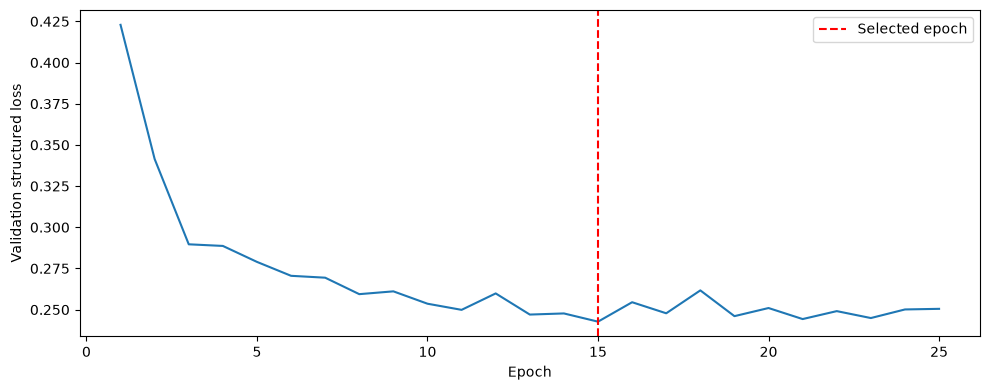

In [91]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
model = StructuredTCN(4, 4, HORIZON, channels=CHANNELS,
                      kernel_size=KERNEL_SIZE, dropout=DROPOUT).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
train_loader = make_loader(X[masks['Train']], y[masks['Train']], shuffle=True)
validation_loader = make_loader(X[masks['Validation']], y[masks['Validation']])
best_validation_loss, best_state, best_epoch, stale = float('inf'), None, 0, 0
history = []

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    total_loss, samples = 0.0, 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        loss = structured_loss(model(X_batch.to(device)), y_batch.to(device))
        if not torch.isfinite(loss):
            raise ValueError('Non-finite training loss.')
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(X_batch)
        samples += len(X_batch)
    model.eval()
    with torch.no_grad():
        validation_losses = [
            structured_loss(model(X_batch.to(device)), y_batch.to(device)).item()
            for X_batch, y_batch in validation_loader
        ]
    validation_loss = float(np.mean(validation_losses))
    if not np.isfinite(validation_loss):
        raise ValueError('Non-finite validation structured loss.')
    history.append({'epoch': epoch, 'training_loss': total_loss / samples,
                    'validation_structured_loss': validation_loss})
    if validation_loss < best_validation_loss:
        best_validation_loss, best_epoch, stale = validation_loss, epoch, 0
        best_state = copy.deepcopy(model.state_dict())
    else:
        stale += 1
    print(f'Epoch {epoch:02d}: loss={total_loss / samples:.4f}, validation structured loss={validation_loss:.4f}')
    if stale >= PATIENCE:
        print('Early stopping.')
        break

if best_state is None:
    raise RuntimeError('No valid checkpoint was found.')
model.load_state_dict(best_state)
history = pd.DataFrame(history)
print(f'Selected epoch: {best_epoch}; validation structured loss: {best_validation_loss:.4f}')
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history['epoch'], history['validation_structured_loss'])
ax.axvline(best_epoch, color='red', linestyle='--', label='Selected epoch')
ax.set(xlabel='Epoch', ylabel='Validation structured loss')
ax.legend()
plt.tight_layout()
plt.show()

## 6. Evaluate the early test period

Use the restored checkpoint directly. Predictions use earlier observed data, with fixed weights and training-only scalers. Persistence predicts today's value from yesterday's observation, including the first test day. It is evaluated on exactly the same dates.

In [92]:
test_mask = masks['Test']
test_dates = dates[test_mask]
actual = df.to_numpy()[positions[test_mask]]
predicted = predict_original(model, X[test_mask])
persistence = df.to_numpy()[positions[test_mask] - 1]
rmse_table = pd.DataFrame({
    'Structured TCN RMSE': np.sqrt(np.mean((predicted - actual) ** 2, axis=0)),
    'Persistence RMSE': np.sqrt(np.mean((persistence - actual) ** 2, axis=0)),
    'Unit': ['requests' if 'count' in name else 'TB' for name in FEATURE_NAMES],
}, index=pd.Index(FEATURE_NAMES, name='Variable'))
display(rmse_table)

assert (predicted >= 0).all()
constraint_rows = []
for access_col, hit_col, miss_col, unit in [(0, 2, 4, 'count'), (1, 3, 5, 'size')]:
    np.testing.assert_allclose(predicted[:, access_col],
                               predicted[:, hit_col] + predicted[:, miss_col],
                               rtol=1e-6, atol=1e-6)
    constraint_rows.append({
        'Variable type': unit,
        'Minimum predicted miss': predicted[:, miss_col].min(),
        'Maximum identity error': np.abs(predicted[:, access_col] - predicted[:, hit_col] - predicted[:, miss_col]).max(),
    })
display(pd.DataFrame(constraint_rows))

,Structured TCN RMSE,Persistence RMSE,Unit
Variable,,,
access_count,21331.883123,18490.825731,requests
access_size,13.319482,15.547086,TB
hit_count,15976.859425,13235.552726,requests
hit_size,8.412053,9.892665,TB
miss_count,8411.036865,8402.918878,requests
miss_size,6.446955,7.293379,TB


,Variable type,Minimum predicted miss,Maximum identity error
0,count,1933.359899,3.637979e-12
1,size,1.331976,1.776357e-15


## 7. Inspect actual and predicted trajectories

Inspect miss_count and miss_size first. The remaining variables help distinguish access-volume errors from ratio-related errors. Curves and RMSE describe this period; they do not prove why the later-period forecast failed.

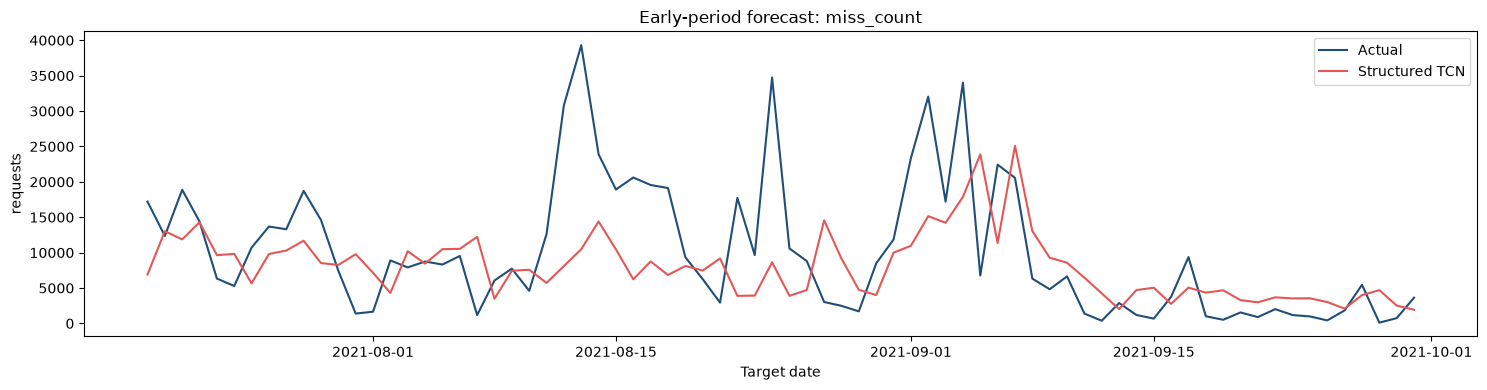

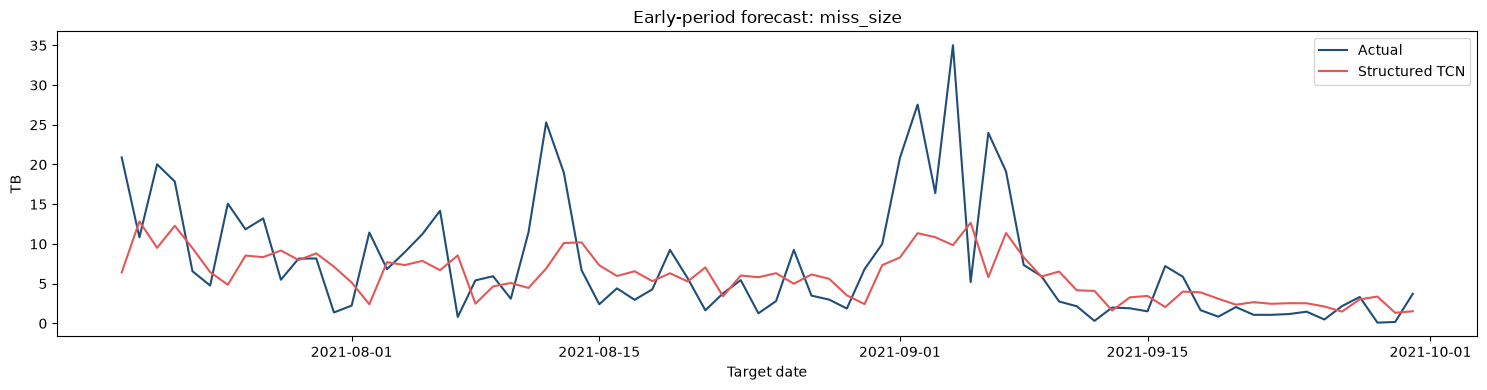

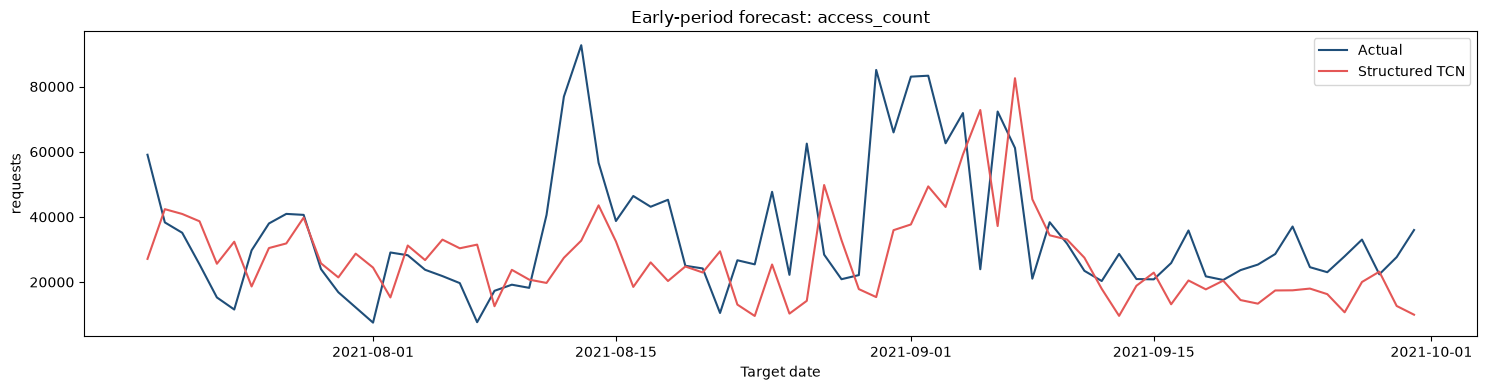

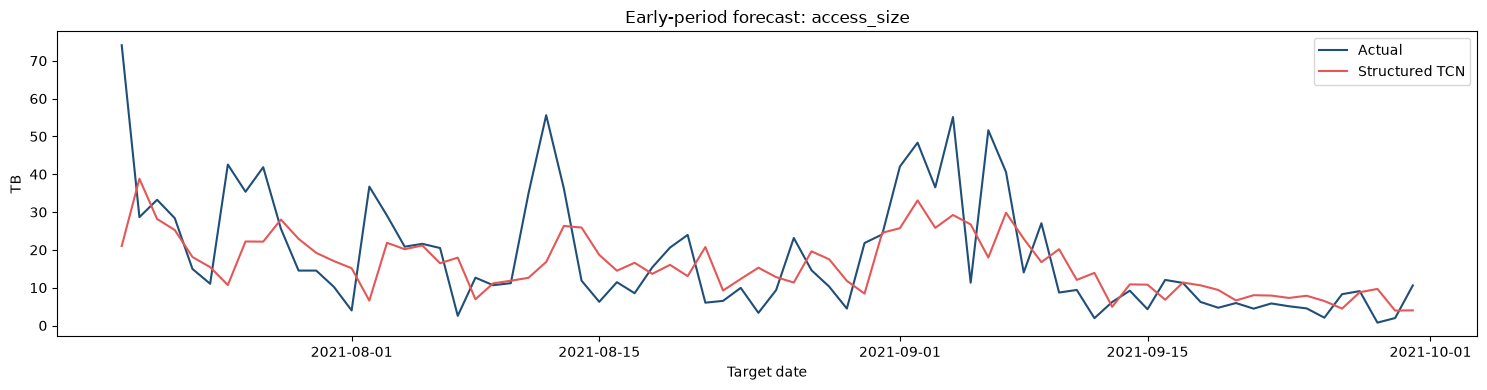

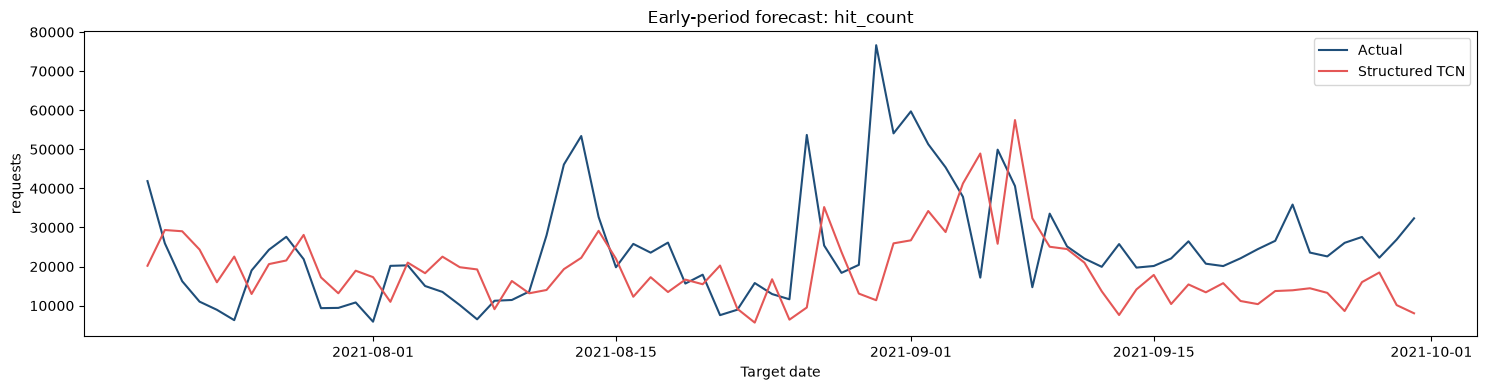

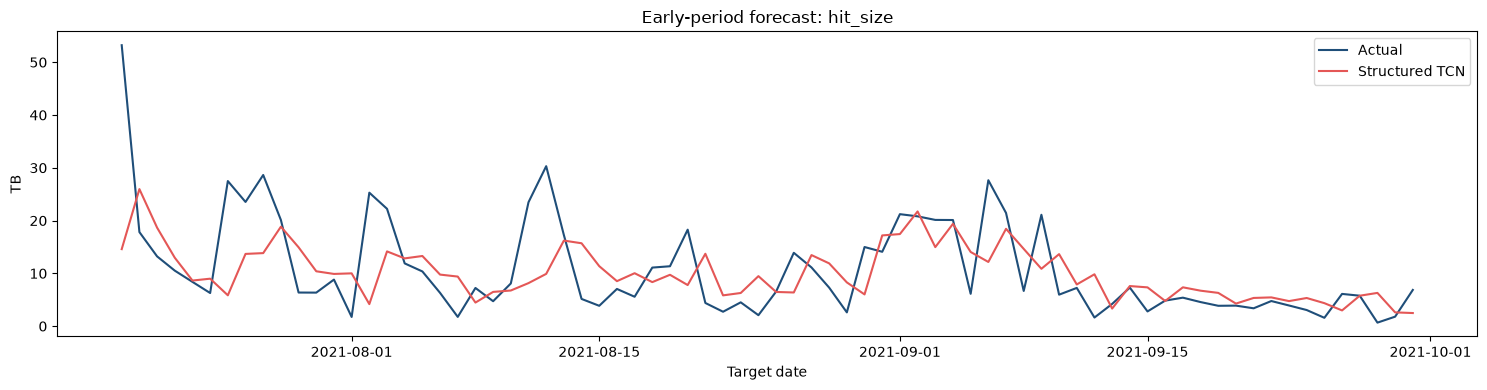

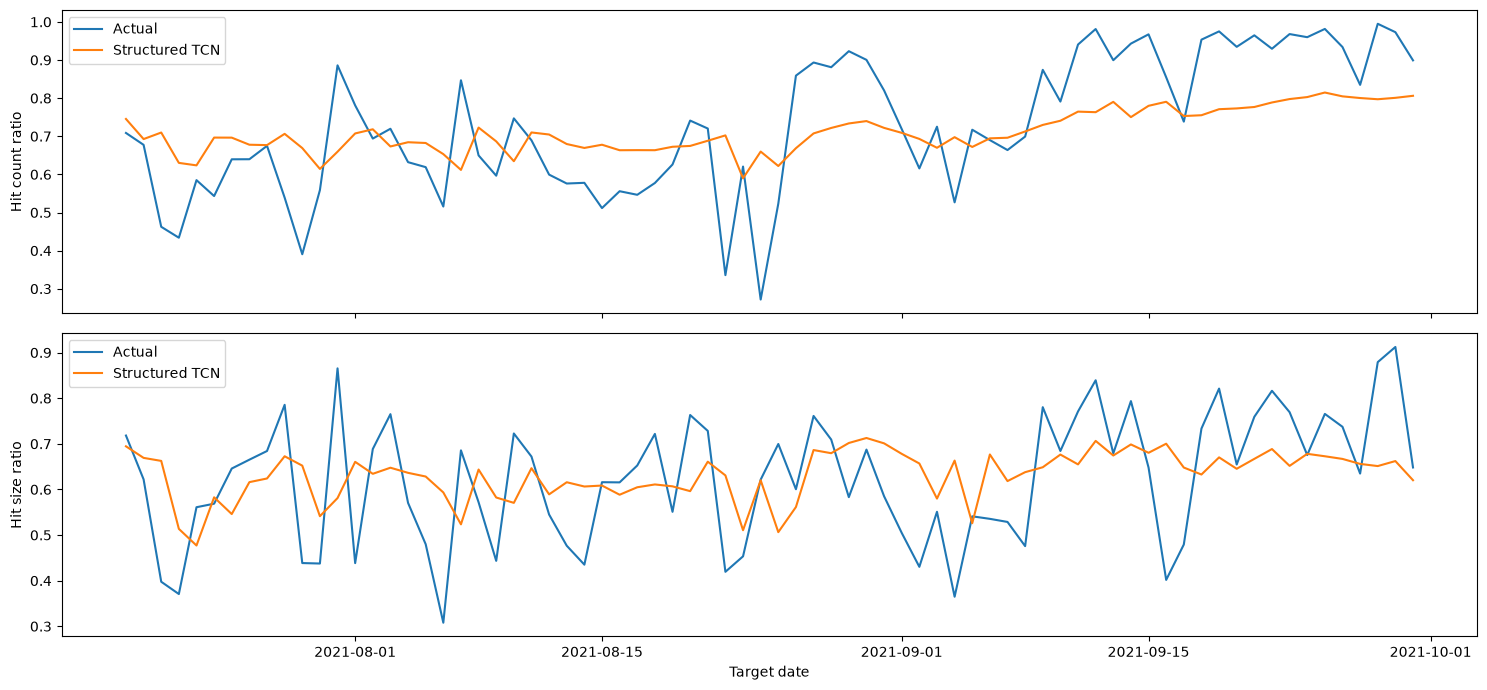

In [93]:
for name in ['miss_count', 'miss_size', 'access_count', 'access_size', 'hit_count', 'hit_size']:
    i = FEATURE_NAMES.index(name)
    unit = 'requests' if 'count' in name else 'TB'
    fig, ax = plt.subplots(figsize=(15, 4))
    ax.plot(test_dates, actual[:, i], label='Actual', color='#1F4E79')
    ax.plot(test_dates, predicted[:, i], label='Structured TCN', color='#E45756')
    ax.set(title=f'Early-period forecast: {name}', xlabel='Target date', ylabel=unit)
    ax.legend()
    fig.tight_layout()
    plt.show()

# Ratios are reconstructed from access and hit; zero-access days are omitted.
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
for ax, (access_col, hit_col, label) in zip(axes, [(0, 2, 'Hit count ratio'), (1, 3, 'Hit size ratio')]):
    actual_ratio = np.divide(actual[:, hit_col], actual[:, access_col],
                             out=np.full(len(actual), np.nan), where=actual[:, access_col] > 0)
    predicted_ratio = np.divide(predicted[:, hit_col], predicted[:, access_col],
                                out=np.full(len(predicted), np.nan), where=predicted[:, access_col] > 0)
    ax.plot(test_dates, actual_ratio, label='Actual')
    ax.plot(test_dates, predicted_ratio, label='Structured TCN')
    ax.set_ylabel(label)
    ax.legend()
axes[-1].set_xlabel('Target date')
fig.tight_layout()
plt.show()

## 8. Save this experiment

Save results in a separate early-baseline folder. Previous experiments are not overwritten.

In [94]:
output_dir = Path('results') / f'regime1_{LOOKBACK}day_70_15_15_structured_loss'
output_dir.mkdir(parents=True, exist_ok=True)
rmse_table.to_csv(output_dir / 'test_rmse.csv')
history.to_csv(output_dir / 'training_history.csv', index=False)
prediction_table = pd.DataFrame(index=test_dates)
prediction_table.index.name = 'target_date'
for i, name in enumerate(FEATURE_NAMES):
    prediction_table[name + '_actual'] = actual[:, i]
    prediction_table[name + '_predicted'] = predicted[:, i]
    prediction_table[name + '_persistence'] = persistence[:, i]
prediction_table.to_csv(output_dir / 'test_predictions.csv')
torch.save({
    'state_dict': {key: value.detach().cpu() for key, value in model.state_dict().items()},
    'input_scaler': input_scaler, 'log_target_scaler': log_target_scaler,
    'best_epoch': best_epoch, 'seed': SEED, 'lookback': LOOKBACK,
    'channels': CHANNELS, 'kernel_size': KERNEL_SIZE, 'dropout': DROPOUT,
    'learning_rate': LEARNING_RATE, 'selection_target': SELECTION_TARGET,
    'train_end': str(TRAIN_END.date()), 'validation_end': str(VALIDATION_END.date()),
    'feature_names': FEATURE_NAMES,
}, output_dir / 'selected_model.pt')
print('Saved results to:', output_dir.resolve())

Saved results to: /Users/dengyingxin/Desktop/xcache/week3/results/regime1_28day_70_15_15_structured_loss


## 9. Week 2 Direct TCN with non-negative miss predictions

Directly predict all six standardized variables with the Week 2 TCN architecture. Fit the scaler on training rows only and reuse the same target dates, lookback, seed, and hyperparameters.

Train and select checkpoints using mean validation batch MSE on the six standardized targets, as in the Week 2 direct baseline. After inverse transformation, clip miss_count and miss_size at zero. This is an output postprocessing constraint, not a constraint inside the training loss. Do not clip standardized values at zero: standardized zero represents the training mean.

The two additive identities are not enforced. The other four outputs remain unconstrained. Compare the clipped predictions with the Structured TCN and persistence on identical test dates.


In [95]:
direct_values = df[FEATURE_NAMES].to_numpy(dtype=np.float32)
direct_scaler = StandardScaler().fit(direct_values[train_rows])
direct_scaled = direct_scaler.transform(direct_values).astype(np.float32)
direct_X = np.asarray([direct_scaled[p - LOOKBACK:p] for p in positions], dtype=np.float32)
direct_y = direct_scaled[positions, None, :]
assert len(direct_X) == len(X)
direct_train_loader = make_loader(direct_X[masks['Train']], direct_y[masks['Train']], shuffle=True)
direct_validation_loader = make_loader(direct_X[masks['Validation']], direct_y[masks['Validation']])
print('Direct train/validation/test samples:', [int(masks[k].sum()) for k in masks])


Direct train/validation/test samples: [313, 73, 74]


### Train the Direct TCN from scratch

The best validation-MSE checkpoint is restored before testing. Test values do not participate in training or checkpoint selection.

Epoch 01: validation MSE=0.71784
Epoch 02: validation MSE=0.67102
Epoch 03: validation MSE=0.66812
Epoch 04: validation MSE=0.65736
Epoch 05: validation MSE=0.66097
Epoch 06: validation MSE=0.65828
Epoch 07: validation MSE=0.67046
Epoch 08: validation MSE=0.66269
Epoch 09: validation MSE=0.66439
Epoch 10: validation MSE=0.66828
Epoch 11: validation MSE=0.67544
Epoch 12: validation MSE=0.67973
Epoch 13: validation MSE=0.67816
Epoch 14: validation MSE=0.68228
Early stopping.
Selected epoch: 4; validation MSE: 0.65736


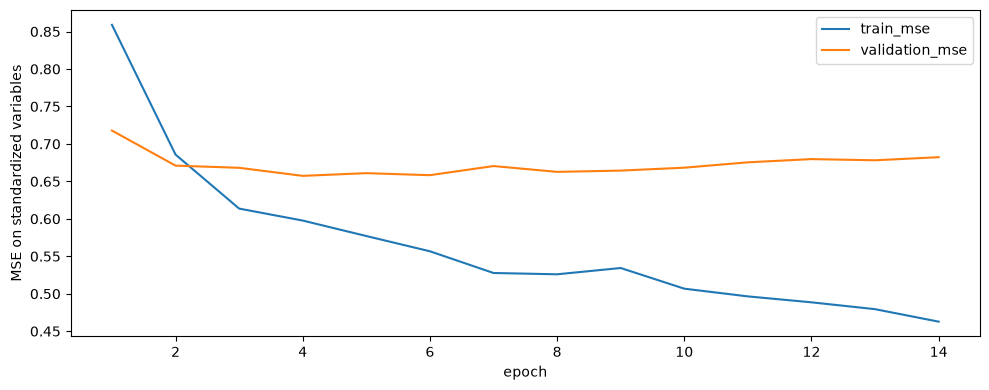

In [96]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
direct_model = TCNForecaster(6, 6, HORIZON, channels=CHANNELS,
                             kernel_size=KERNEL_SIZE, dropout=DROPOUT).to(device)
direct_optimizer = torch.optim.Adam(direct_model.parameters(), lr=LEARNING_RATE)
direct_criterion = nn.MSELoss()
direct_best_loss, direct_best_state = float('inf'), None
direct_best_epoch, direct_stale = 0, 0
direct_history_rows = []

for epoch in range(1, MAX_EPOCHS + 1):
    direct_model.train()
    batch_losses = []
    for X_batch, y_batch in direct_train_loader:
        direct_optimizer.zero_grad()
        loss = direct_criterion(direct_model(X_batch.to(device)), y_batch.to(device))
        if not torch.isfinite(loss):
            raise ValueError('Non-finite direct training loss.')
        loss.backward()
        direct_optimizer.step()
        batch_losses.append(loss.item())
    direct_model.eval()
    with torch.no_grad():
        validation_losses = [
            direct_criterion(direct_model(x.to(device)), target.to(device)).item()
            for x, target in direct_validation_loader
        ]
    validation_loss = float(np.mean(validation_losses))
    if not np.isfinite(validation_loss):
        raise ValueError('Non-finite direct validation loss.')
    direct_history_rows.append({'epoch': epoch, 'train_mse': np.mean(batch_losses),
                                'validation_mse': validation_loss})
    if validation_loss < direct_best_loss:
        direct_best_loss = validation_loss
        direct_best_epoch = epoch
        direct_best_state = copy.deepcopy(direct_model.state_dict())
        direct_stale = 0
    else:
        direct_stale += 1
    print(f'Epoch {epoch:02d}: validation MSE={validation_loss:.5f}')
    if direct_stale >= PATIENCE:
        print('Early stopping.')
        break

if direct_best_state is None:
    raise RuntimeError('No valid Direct TCN checkpoint.')
direct_model.load_state_dict(direct_best_state)
direct_history = pd.DataFrame(direct_history_rows)
print(f'Selected epoch: {direct_best_epoch}; validation MSE: {direct_best_loss:.5f}')
direct_history.plot(x='epoch', y=['train_mse', 'validation_mse'], figsize=(10, 4))
plt.ylabel('MSE on standardized variables')
plt.tight_layout()
plt.show()


### Reconstruct, constrain miss, and compare RMSE

Report how many raw negative miss outputs are clipped. Identity errors are diagnostics only; the direct model is not required to satisfy access = hit + miss.

In [97]:
direct_model.eval()
direct_batches = []
with torch.no_grad():
    for start in range(0, int(masks['Test'].sum()), BATCH_SIZE):
        batch = direct_X[masks['Test']][start:start + BATCH_SIZE]
        tensor = torch.tensor(batch.transpose(0, 2, 1).tolist(), dtype=torch.float32).to(device)
        direct_batches.append(np.asarray(direct_model(tensor).cpu().tolist(), dtype=np.float64))
direct_raw = direct_scaler.inverse_transform(np.concatenate(direct_batches)[:, 0, :])
assert np.isfinite(direct_raw).all()
direct_predicted = direct_raw.copy()
direct_miss_indices = [FEATURE_NAMES.index('miss_count'), FEATURE_NAMES.index('miss_size')]
direct_predicted[:, direct_miss_indices] = np.maximum(direct_predicted[:, direct_miss_indices], 0)
assert (direct_predicted[:, direct_miss_indices] >= 0).all()

direct_checks = pd.DataFrame({
    'Variable': ['miss_count', 'miss_size'],
    'Clipped negative predictions': (direct_raw[:, direct_miss_indices] < 0).sum(axis=0),
    'Minimum final prediction': direct_predicted[:, direct_miss_indices].min(axis=0),
})
display(direct_checks)
direct_comparison = rmse_table.copy()
direct_comparison.insert(1, 'Direct TCN RMSE (non-negative miss)',
                         np.sqrt(np.mean((direct_predicted - actual) ** 2, axis=0)))
display(direct_comparison)
for a, h, m, label in [(0, 2, 4, 'count'), (1, 3, 5, 'size')]:
    difference = np.abs(direct_predicted[:, a] - direct_predicted[:, h] - direct_predicted[:, m])
    print(f'Maximum direct {label} identity error: {difference.max():.6f}')


,Variable,Clipped negative predictions,Minimum final prediction
0,miss_count,0,3266.219405
1,miss_size,0,4.099916


,Structured TCN RMSE,Direct TCN RMSE (non-negative miss),Persistence RMSE,Unit
Variable,,,,
access_count,21331.883123,17150.892191,18490.825731,requests
access_size,13.319482,14.564942,15.547086,TB
hit_count,15976.859425,12876.737412,13235.552726,requests
hit_size,8.412053,9.016610,9.892665,TB
miss_count,8411.036865,7782.872630,8402.918878,requests
miss_size,6.446955,6.483903,7.293379,TB


Maximum direct count identity error: 9716.444871
Maximum direct size identity error: 17.018083


### Direct and structured predictions on the same dates

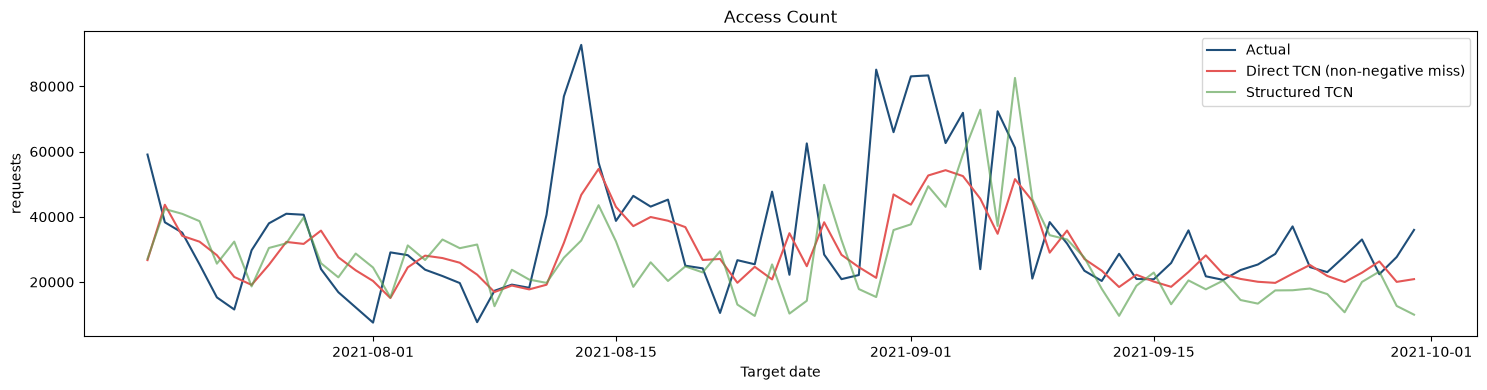

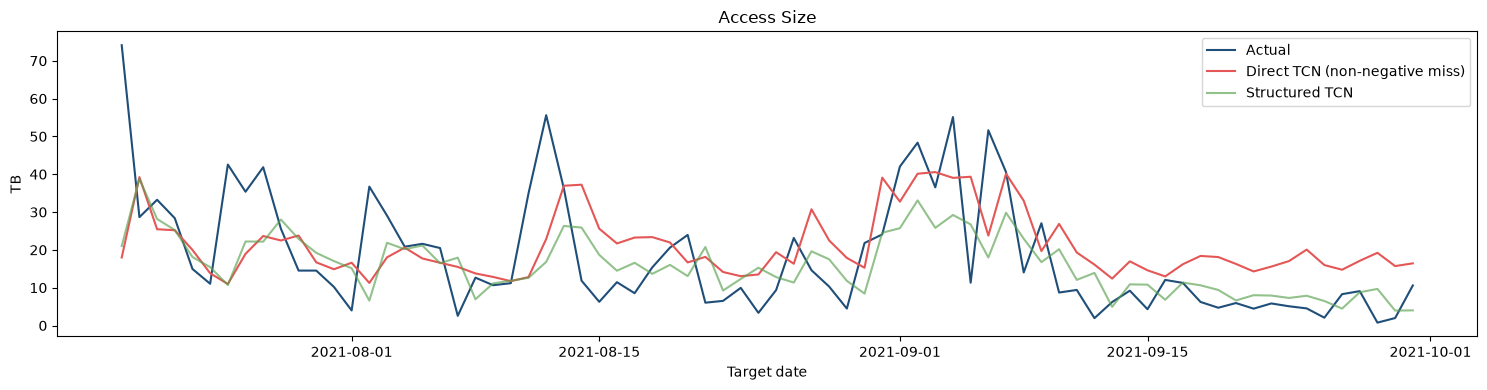

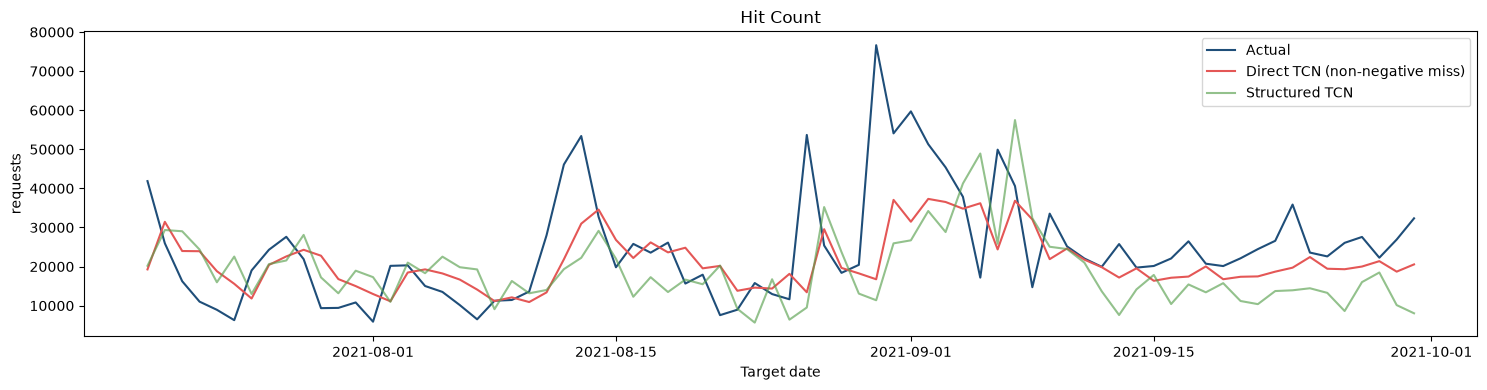

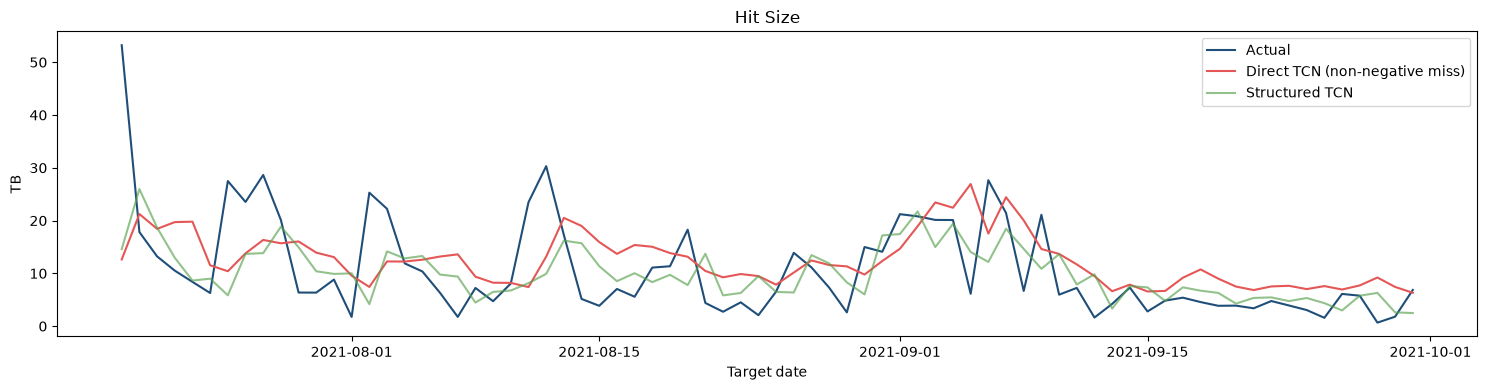

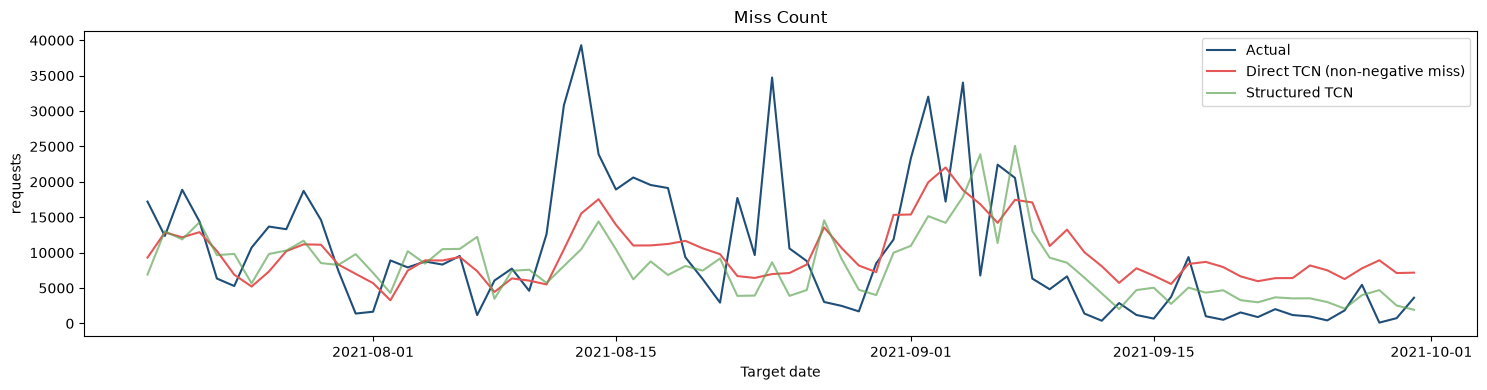

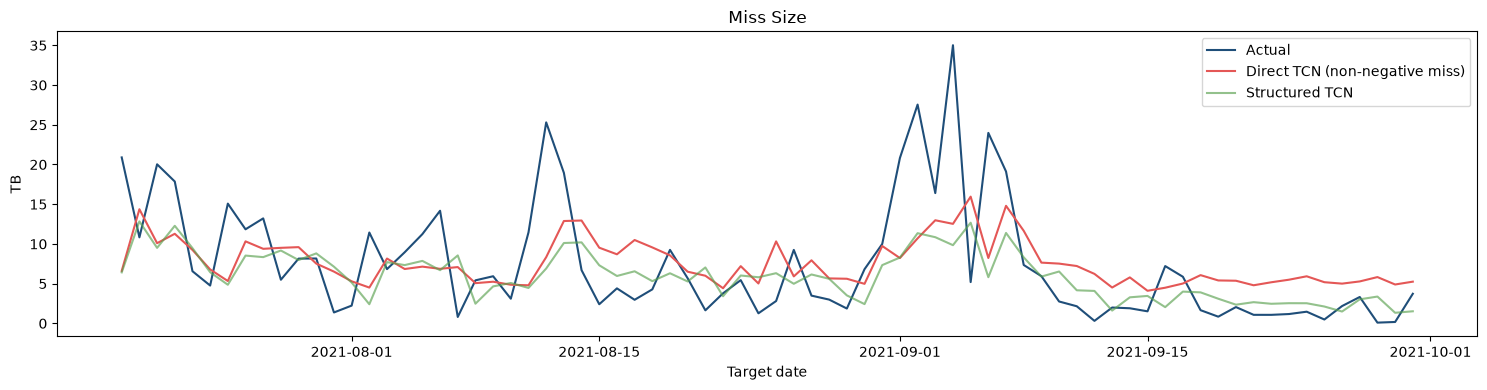

Saved direct baseline results to: /Users/dengyingxin/Desktop/xcache/week3/results/regime1_28day_direct_nonnegative_miss


In [98]:
for i, name in enumerate(FEATURE_NAMES):
    fig, ax = plt.subplots(figsize=(15, 4))
    ax.plot(test_dates, actual[:, i], label='Actual', color='#1F4E79')
    ax.plot(test_dates, direct_predicted[:, i], label='Direct TCN (non-negative miss)', color='#E45756')
    ax.plot(test_dates, predicted[:, i], label='Structured TCN', alpha=0.65, color='#59A14F')
    ax.set(title=name.replace('_', ' ').title(), xlabel='Target date',
           ylabel='requests' if 'count' in name else 'TB')
    ax.legend()
    fig.tight_layout()
    plt.show()

direct_output_dir = Path('results') / f'regime1_{LOOKBACK}day_direct_nonnegative_miss'
direct_output_dir.mkdir(parents=True, exist_ok=True)
direct_comparison.to_csv(direct_output_dir / 'test_rmse_comparison.csv')
direct_history.to_csv(direct_output_dir / 'training_history.csv', index=False)
direct_checks.to_csv(direct_output_dir / 'clipping_checks.csv', index=False)
direct_predictions_table = pd.DataFrame(index=test_dates)
direct_predictions_table.index.name = 'target_date'
for i, name in enumerate(FEATURE_NAMES):
    direct_predictions_table[name + '_actual'] = actual[:, i]
    direct_predictions_table[name + '_direct_raw'] = direct_raw[:, i]
    direct_predictions_table[name + '_direct'] = direct_predicted[:, i]
direct_predictions_table.to_csv(direct_output_dir / 'test_predictions.csv')
print('Saved direct baseline results to:', direct_output_dir.resolve())


## 10. Five-block lookback experiments

Compare windows from 7 to 120 days over the full dataset (2020-05-31 through 2024-03-31), using chronological 70/15/15 boundaries. Five residual blocks each contain two convolutions, with 32 hidden channels, kernel size 3, and dilations [1, 2, 4, 8, 16]. The receptive field is 125 days.

Both Structured and Direct TCNs are scanned by default (32 training runs). Set SCAN_MODELS to one model name to run only that family. For a common selection rule, each model is ranked by validation hit_size RMSE in original TB units. Internal training losses remain different, but do not determine the selected window.

All windows share training target dates starting after the first 120 observations, and the same validation dates. Independent scalers use full-dataset training rows only; earlier first-regime experiments remain separate. Consequently, these runs have fewer training targets than the earlier 28-day baseline, so previous results are not a controlled depth-only comparison.

The test period is not evaluated during this scan. Direct miss predictions are clipped at zero after inverse scaling; Structured predictions retain the additive constraints.


In [12]:
SCAN_LOOKBACKS = [7, 14, 28, 35, 42, 49, 56, 63, 70, 77, 84, 91, 98, 105, 112, 120]
SCAN_MODELS = ['structured', 'direct']
SCAN_CHANNELS = (32, 32, 32, 32, 32)
SCAN_MAX_EPOCHS, SCAN_PATIENCE = MAX_EPOCHS, PATIENCE
# One common validation metric for Direct, Structured, and LSTM model selection.
PRIMARY_SELECTION_VARIABLE = 'hit_size'
PRIMARY_SELECTION_INDEX = FEATURE_NAMES.index(PRIMARY_SELECTION_VARIABLE)
scan_output_dir = Path('results') / 'full_dataset_five_block_lookback'
scan_output_dir.mkdir(parents=True, exist_ok=True)

# Reload the original file to avoid double conversion or reusing the first regime.
scan_df = pd.read_pickle(data_file).loc['2020-05-31':'2024-03-31', FEATURE_NAMES].copy()
scan_df[['access_size', 'hit_size', 'miss_size']] /= 1000 ** 4
assert scan_df.index.equals(pd.date_range('2020-05-31', '2024-03-31', freq='D'))
assert len(scan_df) == 1401
scan_raw = scan_df.to_numpy(dtype=np.float32)
assert np.isfinite(scan_raw).all() and (scan_raw >= 0).all()
scan_train_end = int(len(scan_df) * 0.70)
scan_validation_end = int(len(scan_df) * (0.70 + 0.15))
for label, left, right in [
    ('Train rows', 0, scan_train_end),
    ('Validation rows', scan_train_end, scan_validation_end),
    ('Test rows (reserved)', scan_validation_end, len(scan_df)),
]:
    print(label, scan_df.index[left].date(), 'to', scan_df.index[right - 1].date(), right - left)

scan_count_ratio = np.divide(scan_raw[:, 2], scan_raw[:, 0],
                             out=np.zeros(len(scan_df)), where=scan_raw[:, 0] > 0)
scan_size_ratio = np.divide(scan_raw[:, 3], scan_raw[:, 1],
                            out=np.zeros(len(scan_df)), where=scan_raw[:, 1] > 0)
scan_structured = np.column_stack([
    np.log1p(scan_raw[:, 0]), np.log1p(scan_raw[:, 1]), scan_count_ratio, scan_size_ratio,
]).astype(np.float32)
assert ((scan_structured[:, 2:] >= 0) & (scan_structured[:, 2:] <= 1)).all()
scan_input_scaler = StandardScaler().fit(scan_structured[:scan_train_end])
scan_log_scaler = StandardScaler().fit(scan_structured[:scan_train_end, :2])
scan_inputs = scan_input_scaler.transform(scan_structured).astype(np.float32)
scan_targets = np.column_stack([
    scan_log_scaler.transform(scan_structured[:, :2]), scan_structured[:, 2:],
]).astype(np.float32)
scan_direct_scaler = StandardScaler().fit(scan_raw[:scan_train_end])
scan_direct_values = scan_direct_scaler.transform(scan_raw).astype(np.float32)

scan_receptive_field = 1 + 2 * (KERNEL_SIZE - 1) * sum(2 ** i for i in range(len(SCAN_CHANNELS)))
assert scan_receptive_field >= max(SCAN_LOOKBACKS)
assert HORIZON == 1
# Equal training target dates for every window; no test target participates.
scan_positions = np.arange(max(SCAN_LOOKBACKS), scan_validation_end)
scan_dates = scan_df.index[scan_positions]
scan_train_mask = scan_positions < scan_train_end
scan_validation_mask = scan_positions >= scan_train_end
scan_validation_actual = scan_raw[scan_positions[scan_validation_mask]]
print('Receptive field:', scan_receptive_field)
print('Shared training targets:', int(scan_train_mask.sum()))
print('Shared validation targets:', int(scan_validation_mask.sum()))


Train rows 2020-05-31 to 2023-02-04 980
Validation rows 2023-02-05 to 2023-09-02 210
Test rows (reserved) 2023-09-03 to 2024-03-31 211
Receptive field: 125
Shared training targets: 860
Shared validation targets: 210


### Fit one window from scratch

Reset the seed for each run. At every epoch, reconstruct predictions in original units and retain the checkpoint with the lowest validation `hit_size` RMSE (TB). Internal training losses remain model-specific. Save each checkpoint with its scalers and configuration.

In [13]:
def decode_scan_prediction(kind, raw_prediction):
    if kind == 'structured':
        logs = scan_log_scaler.inverse_transform(raw_prediction[:, :2])
        access = np.maximum(np.expm1(logs), 0)
        ratios = np.clip(raw_prediction[:, 2:], 0, 1)
        return np.column_stack([access[:, 0], access[:, 1],
                                access[:, 0] * ratios[:, 0], access[:, 1] * ratios[:, 1],
                                access[:, 0] * (1 - ratios[:, 0]), access[:, 1] * (1 - ratios[:, 1])])
    prediction = scan_direct_scaler.inverse_transform(raw_prediction)
    prediction[:, [4, 5]] = np.maximum(prediction[:, [4, 5]], 0)
    return prediction

def fit_scan_window(kind, lookback):
    if kind not in ['structured', 'direct']:
        raise ValueError('Unknown model family.')
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    if kind == 'structured':
        source, target = scan_inputs, scan_targets
        scan_model = StructuredTCN(4, 4, HORIZON, channels=SCAN_CHANNELS,
                                   kernel_size=KERNEL_SIZE, dropout=DROPOUT).to(device)
        criterion = structured_loss
    else:
        source, target = scan_direct_values, scan_direct_values
        scan_model = TCNForecaster(6, 6, HORIZON, channels=SCAN_CHANNELS,
                                   kernel_size=KERNEL_SIZE, dropout=DROPOUT).to(device)
        criterion = nn.MSELoss()
    features = np.asarray([source[p - lookback:p] for p in scan_positions], dtype=np.float32)
    labels = target[scan_positions, None, :]
    training_loader = make_loader(features[scan_train_mask], labels[scan_train_mask], shuffle=True)
    validation_loader = make_loader(features[scan_validation_mask], labels[scan_validation_mask])
    optimizer_run = torch.optim.Adam(scan_model.parameters(), lr=LEARNING_RATE)
    best_selection_rmse, best_loss, state, best_epoch, stale = float('inf'), float('inf'), None, 0, 0
    run_history = []
    for epoch in range(1, SCAN_MAX_EPOCHS + 1):
        scan_model.train()
        losses = []
        for xb, yb in training_loader:
            optimizer_run.zero_grad()
            loss = criterion(scan_model(xb.to(device)), yb.to(device))
            if not torch.isfinite(loss):
                raise ValueError('Non-finite training loss.')
            loss.backward()
            optimizer_run.step()
            losses.append(loss.item())
        scan_model.eval()
        with torch.no_grad():
            val_loss = float(np.mean([
                criterion(scan_model(xb.to(device)), yb.to(device)).item()
                for xb, yb in validation_loader
            ]))
        if not np.isfinite(val_loss):
            raise ValueError('Non-finite validation loss.')
        raw_batches = []
        with torch.no_grad():
            for xb, _ in validation_loader:
                raw_batches.append(np.asarray(scan_model(xb.to(device)).cpu().tolist(), dtype=np.float64))
        validation_prediction = decode_scan_prediction(kind, np.concatenate(raw_batches)[:, 0, :])
        selection_rmse = float(np.sqrt(np.mean((validation_prediction[:, PRIMARY_SELECTION_INDEX] - scan_validation_actual[:, PRIMARY_SELECTION_INDEX]) ** 2)))
        run_history.append({'epoch': epoch, 'train_loss': np.mean(losses), 'validation_loss': val_loss,
                            f'validation_{PRIMARY_SELECTION_VARIABLE}_rmse': selection_rmse})
        if selection_rmse < best_selection_rmse:
            best_selection_rmse, best_loss, state, best_epoch, stale = selection_rmse, val_loss, copy.deepcopy(scan_model.state_dict()), epoch, 0
        else:
            stale += 1
        if stale >= SCAN_PATIENCE:
            break
    if state is None:
        raise RuntimeError('No valid checkpoint.')
    scan_model.load_state_dict(state)
    scan_model.eval()
    batches = []
    with torch.no_grad():
        for xb, _ in validation_loader:
            batches.append(np.asarray(scan_model(xb.to(device)).cpu().tolist(), dtype=np.float64))
    raw_prediction = np.concatenate(batches)[:, 0, :]
    prediction = decode_scan_prediction(kind, raw_prediction)
    assert np.isfinite(prediction).all()
    assert (prediction[:, [4, 5]] >= 0).all()
    if kind == 'structured':
        np.testing.assert_allclose(prediction[:, 0], prediction[:, 2] + prediction[:, 4], rtol=1e-6, atol=1e-6)
        np.testing.assert_allclose(prediction[:, 1], prediction[:, 3] + prediction[:, 5], rtol=1e-6, atol=1e-6)
    scores = np.sqrt(np.mean((prediction - scan_validation_actual) ** 2, axis=0))
    result = {
        'model': kind, 'lookback': lookback, 'blocks': len(SCAN_CHANNELS),
        'receptive_field': scan_receptive_field, 'best_epoch': best_epoch,
        'epochs_run': len(run_history), 'validation_loss': best_loss,
        f'validation_{PRIMARY_SELECTION_VARIABLE}_rmse': best_selection_rmse,
        **dict(zip(FEATURE_NAMES, scores)),
    }
    stem = f'{kind}_{lookback}day'
    pd.DataFrame(run_history).to_csv(scan_output_dir / f'{stem}_history.csv', index=False)
    torch.save({
        'state_dict': {key: value.detach().cpu() for key, value in state.items()},
        'result': result, 'channels': SCAN_CHANNELS, 'dropout': DROPOUT,
        'kernel_size': KERNEL_SIZE, 'seed': SEED, 'learning_rate': LEARNING_RATE,
        'train_end': str(scan_df.index[scan_train_end - 1].date()), 'validation_end': str(scan_df.index[scan_validation_end - 1].date()),
        'common_target_start': str(scan_dates.min().date()),
        'input_scaler': scan_input_scaler if kind == 'structured' else scan_direct_scaler,
        'log_target_scaler': scan_log_scaler if kind == 'structured' else None,
        'feature_names': FEATURE_NAMES,
    }, scan_output_dir / f'{stem}_checkpoint.pt')
    return result


### Run the window scan

The best epoch is selected independently for each window. Save the accumulated results after each run. Test metrics are intentionally absent.

In [104]:
scan_rows = []
for kind in SCAN_MODELS:
    for lookback in SCAN_LOOKBACKS:
        print(f'Training {kind}: lookback={lookback}, blocks=5, channels=32')
        result = fit_scan_window(kind, lookback)
        scan_rows.append(result)
        print(f"Best epoch={result['best_epoch']}, validation {PRIMARY_SELECTION_VARIABLE} RMSE={result[f'validation_{PRIMARY_SELECTION_VARIABLE}_rmse']:.5f}")
        pd.DataFrame(scan_rows).to_csv(scan_output_dir / 'validation_results.csv', index=False)

scan_results = pd.DataFrame(scan_rows)
scan_top_two = {}
for kind in SCAN_MODELS:
    ranked = scan_results[scan_results['model'] == kind].sort_values(f'validation_{PRIMARY_SELECTION_VARIABLE}_rmse', kind='stable')
    display(ranked.reset_index(drop=True))
    scan_top_two[kind] = ranked.head(2)['lookback'].astype(int).tolist()
print(f'Top two windows by validation {PRIMARY_SELECTION_VARIABLE} RMSE:', scan_top_two)


Training structured: lookback=7, blocks=5, channels=32


Best epoch=11, validation loss=0.72061
Training structured: lookback=14, blocks=5, channels=32
Best epoch=11, validation loss=0.71396
Training structured: lookback=28, blocks=5, channels=32
Best epoch=7, validation loss=0.71844
Training structured: lookback=35, blocks=5, channels=32
Best epoch=32, validation loss=0.71419
Training structured: lookback=42, blocks=5, channels=32
Best epoch=15, validation loss=0.72150
Training structured: lookback=49, blocks=5, channels=32
Best epoch=15, validation loss=0.72413
Training structured: lookback=56, blocks=5, channels=32
Best epoch=7, validation loss=0.72806
Training structured: lookback=63, blocks=5, channels=32
Best epoch=9, validation loss=0.72681
Training structured: lookback=70, blocks=5, channels=32
Best epoch=9, validation loss=0.71749
Training structured: lookback=77, blocks=5, channels=32
Best epoch=11, validation loss=0.71978
Training structured: lookback=84, blocks=5, channels=32
Best epoch=11, validation loss=0.71801
Training struct

,model,lookback,blocks,receptive_field,best_epoch,epochs_run,validation_loss,access_count,access_size,hit_count,hit_size,miss_count,miss_size
0,structured,91,5,125,27,37,0.713237,13568.005867,39.400343,12186.342388,39.220166,2811.314502,2.569699
1,structured,120,5,125,6,16,0.713783,13717.235496,36.918030,12421.285165,37.131423,2778.126871,3.089540
2,structured,14,5,125,11,21,0.713957,13114.949778,37.540009,11745.281041,37.449889,2728.519036,2.696241
3,structured,35,5,125,32,42,0.714185,13265.546051,38.153777,11937.021679,37.835275,2694.604597,2.452136
4,structured,70,5,125,9,19,0.717492,13550.902623,37.885666,12187.433974,37.642709,2747.750807,2.599164
5,structured,84,5,125,11,21,0.718013,12996.113521,37.594924,11660.925542,37.474767,2762.803292,2.523995
6,structured,112,5,125,9,19,0.718353,13781.213347,38.775823,12451.392790,38.759799,2766.068377,2.537414
7,structured,28,5,125,7,17,0.718443,13939.326163,37.828114,12686.374954,38.153523,2733.702942,2.908836
8,structured,77,5,125,11,21,0.719782,12877.686252,38.365027,11459.682609,38.146278,2807.764020,2.490112
9,structured,7,5,125,11,21,0.720607,13316.514088,36.010817,11963.886845,35.921742,2712.231164,2.656449


,model,lookback,blocks,receptive_field,best_epoch,epochs_run,validation_loss,access_count,access_size,hit_count,hit_size,miss_count,miss_size
0,direct,7,5,125,9,19,1.138642,13245.883109,33.701019,11160.537526,32.262165,3132.241543,2.839556
1,direct,14,5,125,15,25,1.150720,13429.632695,33.995775,11296.916637,32.005272,3293.963470,3.888533
2,direct,84,5,125,9,19,1.165050,13457.686712,34.243517,11566.766185,32.145969,3153.710183,4.346911
3,direct,98,5,125,14,24,1.165296,13852.568013,33.984677,11483.434225,32.194689,2933.194947,4.274476
4,direct,63,5,125,9,19,1.167528,13329.535809,34.581739,11533.641287,32.065369,2950.225074,4.720533
5,direct,28,5,125,11,21,1.174150,13544.681596,34.129511,11678.418532,32.429225,3073.310779,3.908558
6,direct,91,5,125,11,21,1.174188,13733.177390,33.934664,11564.497534,32.086831,3861.126017,5.626901
7,direct,120,5,125,9,19,1.176092,13748.411974,34.164334,11496.583821,32.344448,3404.641774,4.526703
8,direct,35,5,125,9,19,1.177548,13402.559987,34.955754,11330.456875,32.311436,2824.429707,5.039292
9,direct,112,5,125,9,19,1.179940,13386.506999,34.334269,11456.518706,32.272514,3814.972804,5.108310


Top two windows per model family: {'structured': [91, 120], 'direct': [7, 14]}


### Inspect validation RMSE by window

Count RMSE is in requests; size RMSE is in TB. Dashed lines show persistence on the same validation dates. Checkpoint and window ranking above use validation `hit_size` RMSE in TB for every model family.

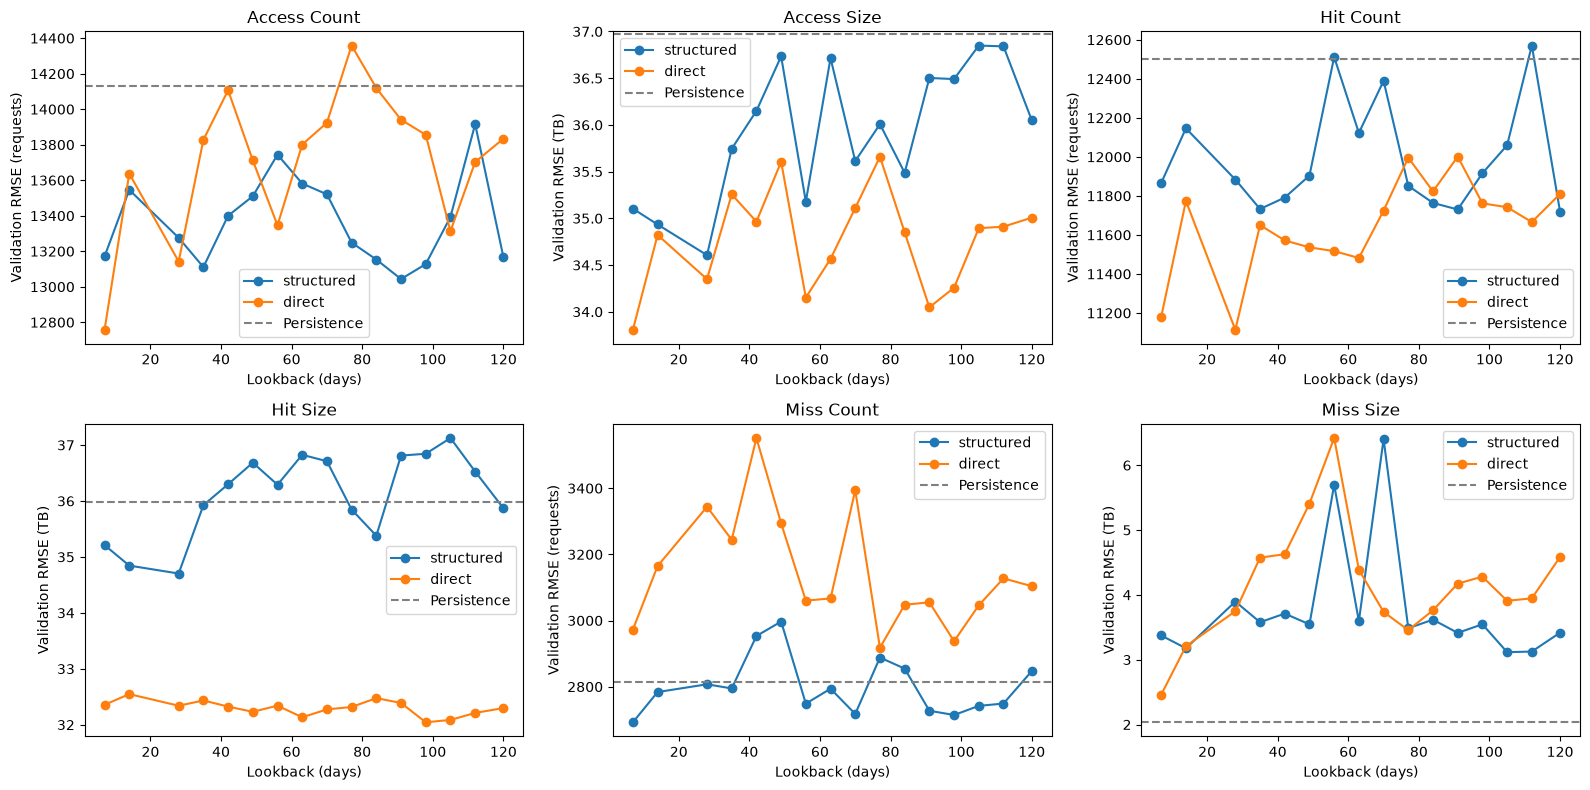

In [15]:
# Load the completed scan results without retraining.
if 'scan_results' not in globals():
    scan_output_dir = Path('results') / 'full_dataset_five_block_lookback'
    scan_results = pd.read_csv(scan_output_dir / 'validation_results.csv')
    
scan_persistence = scan_raw[scan_positions[scan_validation_mask] - 1]
scan_persistence_rmse = np.sqrt(np.mean((scan_persistence - scan_validation_actual) ** 2, axis=0))
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, (name, ax) in enumerate(zip(FEATURE_NAMES, axes.flat)):
    for kind in SCAN_MODELS:
        rows = scan_results[scan_results['model'] == kind].sort_values('lookback')
        ax.plot(rows['lookback'], rows[name], marker='o', label=kind)
    ax.axhline(scan_persistence_rmse[i], linestyle='--', color='gray', label='Persistence')
    ax.set(title=name.replace('_', ' ').title(), xlabel='Lookback (days)',
           ylabel='Validation RMSE (requests)' if 'count' in name else 'Validation RMSE (TB)')
    ax.legend()
fig.tight_layout()
plt.show()


## 11. Final comparison on the full-data held-out test set

Choose the top two five-block structured windows by validation `hit_size` RMSE (TB), then compare them with the Week 2 reference architecture (three blocks and 28 days). The scan used a common day-120 target start for fairness across windows. Here, each selected model uses every available target in the 70% training period; no test observation is used until the final RMSE calculation.


In [114]:
# This also works after restarting the kernel, provided the completed scan CSV exists.
if 'scan_results' not in globals():
    scan_results = pd.read_csv(scan_output_dir / 'validation_results.csv')
FINAL_TOP_K = 2

selected_windows = (scan_results[scan_results['model'] == 'structured']
                    .sort_values(f'validation_{PRIMARY_SELECTION_VARIABLE}_rmse', kind='stable')
                    .head(FINAL_TOP_K)['lookback'].astype(int).tolist())
final_candidates = [
    ('Week 2 reference (3 blocks, 28 days)', 28, (32, 32, 32)),
] + [(f'Five-block candidate ({lookback} days)', lookback, SCAN_CHANNELS)
     for lookback in selected_windows]
display(pd.DataFrame(final_candidates, columns=['model', 'lookback', 'channels']))

def decode_final(raw_output):
    logs = scan_log_scaler.inverse_transform(raw_output[:, :2])
    access = np.maximum(np.expm1(logs), 0)
    ratios = np.clip(raw_output[:, 2:], 0, 1)
    return np.column_stack([access[:, 0], access[:, 1],
                            access[:, 0] * ratios[:, 0], access[:, 1] * ratios[:, 1],
                            access[:, 0] * (1 - ratios[:, 0]), access[:, 1] * (1 - ratios[:, 1])])

def predict_final(model_run, features):
    model_run.eval()
    output_batches = []
    with torch.no_grad():
        for start in range(0, len(features), BATCH_SIZE):
            batch = features[start:start + BATCH_SIZE]
            tensor = torch.tensor(batch.transpose(0, 2, 1).tolist(), dtype=torch.float32).to(device)
            output_batches.append(np.asarray(model_run(tensor).cpu().tolist(), dtype=np.float64))
    return decode_final(np.concatenate(output_batches)[:, 0, :])

def run_final_candidate(label, lookback, channels):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    final_positions = np.arange(lookback, len(scan_df))
    train_mask_final = final_positions < scan_train_end
    validation_mask_final = (final_positions >= scan_train_end) & (final_positions < scan_validation_end)
    test_mask_final = final_positions >= scan_validation_end
    final_features = np.asarray([scan_inputs[p - lookback:p] for p in final_positions], dtype=np.float32)
    final_targets = scan_targets[final_positions, None, :]
    train_loader_final = make_loader(final_features[train_mask_final], final_targets[train_mask_final], shuffle=True)
    validation_loader_final = make_loader(final_features[validation_mask_final], final_targets[validation_mask_final])
    validation_actual_final = scan_raw[final_positions[validation_mask_final]]
    model_run = StructuredTCN(4, 4, HORIZON, channels=channels, kernel_size=KERNEL_SIZE, dropout=DROPOUT).to(device)
    optimizer_run = torch.optim.Adam(model_run.parameters(), lr=LEARNING_RATE)
    best_selection_rmse, best_state, best_epoch, stale = float('inf'), None, 0, 0
    history_rows = []
    for epoch in range(1, SCAN_MAX_EPOCHS + 1):
        model_run.train(); epoch_losses = []
        for xb, yb in train_loader_final:
            optimizer_run.zero_grad()
            loss = structured_loss(model_run(xb.to(device)), yb.to(device))
            loss.backward(); optimizer_run.step(); epoch_losses.append(loss.item())
        validation_prediction = predict_final(model_run, final_features[validation_mask_final])
        selection_rmse = float(np.sqrt(np.mean((validation_prediction[:, PRIMARY_SELECTION_INDEX] - validation_actual_final[:, PRIMARY_SELECTION_INDEX]) ** 2)))
        history_rows.append({'epoch': epoch, 'training_structured_loss': np.mean(epoch_losses),
                             f'validation_{PRIMARY_SELECTION_VARIABLE}_rmse': selection_rmse})
        if selection_rmse < best_selection_rmse:
            best_selection_rmse, best_state, best_epoch, stale = selection_rmse, copy.deepcopy(model_run.state_dict()), epoch, 0
        else:
            stale += 1
        if stale >= SCAN_PATIENCE: break
    model_run.load_state_dict(best_state)
    test_prediction = predict_final(model_run, final_features[test_mask_final])
    test_actual = scan_raw[final_positions[test_mask_final]]
    persistence = scan_raw[final_positions[test_mask_final] - 1]
    return {'model': label, 'lookback': lookback, 'blocks': len(channels), 'best_epoch': best_epoch,
            f'validation_{PRIMARY_SELECTION_VARIABLE}_rmse': best_selection_rmse, 'training_targets': int(train_mask_final.sum()),
            'test_dates': scan_df.index[final_positions[test_mask_final]], 'actual': test_actual,
            'prediction': test_prediction, 'persistence': persistence, 'history': pd.DataFrame(history_rows)}

final_runs = []
for label, lookback, channels in final_candidates:
    print('Training:', label)
    final_runs.append(run_final_candidate(label, lookback, channels))


,model,lookback,channels
0,"Week 2 reference (3 blocks, 28 days)",28,"(32, 32, 32)"
1,Five-block candidate (91 days),91,"(32, 32, 32, 32, 32)"
2,Five-block candidate (120 days),120,"(32, 32, 32, 32, 32)"


Training: Week 2 reference (3 blocks, 28 days)
Training: Five-block candidate (91 days)
Training: Five-block candidate (120 days)


In [17]:
final_output_dir = Path('results') / 'full_dataset_final_test_comparison'
final_output_dir.mkdir(parents=True, exist_ok=True)

# After a kernel restart, display the saved Structured results without retraining.
if 'final_runs' not in globals():
    final_test_results = pd.read_csv(final_output_dir / 'test_rmse_comparison.csv')
    display(final_test_results.pivot(index='variable', columns='model', values='test_rmse'))
    print('Loaded saved Structured final comparison from:', final_output_dir.resolve())
else:
    final_rows = []
    for run_number, run in enumerate(final_runs):
        test_rmse = np.sqrt(np.mean((run['prediction'] - run['actual']) ** 2, axis=0))
        persistence_rmse = np.sqrt(np.mean((run['persistence'] - run['actual']) ** 2, axis=0))
        for i, name in enumerate(FEATURE_NAMES):
            final_rows.append({'model': run['model'], 'lookback': run['lookback'], 'blocks': run['blocks'],
                               'variable': name, 'test_rmse': test_rmse[i], 'persistence_rmse': persistence_rmse[i]})
        safe_name = f"{run_number}_{run['lookback']}day_{run['blocks']}block"
        run['history'].to_csv(final_output_dir / f'{safe_name}_history.csv', index=False)
        predictions = pd.DataFrame(index=run['test_dates'])
        predictions.index.name = 'target_date'
        for i, name in enumerate(FEATURE_NAMES):
            predictions[f'{name}_actual'] = run['actual'][:, i]
            predictions[f'{name}_predicted'] = run['prediction'][:, i]
            predictions[f'{name}_persistence'] = run['persistence'][:, i]
        predictions.to_csv(final_output_dir / f'{safe_name}_predictions.csv')
    final_test_results = pd.DataFrame(final_rows)
    display(final_test_results.pivot(index='variable', columns='model', values='test_rmse'))
    final_test_results.to_csv(final_output_dir / 'test_rmse_comparison.csv', index=False)
    print('Saved final test comparison to:', final_output_dir.resolve())


model,Five-block candidate (14 days),Five-block candidate (28 days),"Week 2 reference (3 blocks, 28 days)"
variable,,,
access_count,12030.892560,13450.049916,12320.137032
access_size,31.080000,31.089353,31.601305
hit_count,11505.059362,12318.950044,11601.231310
hit_size,30.833341,30.530831,31.012691
miss_count,1345.929525,1649.881203,1931.657845
miss_size,2.079509,2.159065,2.806973


Loaded saved Structured final comparison from: /Users/dengyingxin/Desktop/xcache/week3/results/full_dataset_final_test_comparison


## 12. Direct TCN final comparison

Apply the matching selection rule to Direct TCN: select the two five-block Direct windows with the lowest validation `hit_size` RMSE (TB), add the Week 2 Direct reference (three blocks, 28 days), and evaluate every selected model once on the same held-out test dates. Direct TCN clips miss predictions to zero but does not enforce `access = hit + miss`.


In [116]:
direct_selected_windows = (scan_results[scan_results['model'] == 'direct']
                           .sort_values(f'validation_{PRIMARY_SELECTION_VARIABLE}_rmse', kind='stable')
                           .head(FINAL_TOP_K)['lookback'].astype(int).tolist())
direct_final_candidates = [
    ('Week 2 Direct reference (3 blocks, 28 days)', 28, (32, 32, 32)),
] + [(f'Five-block Direct candidate ({lookback} days)', lookback, SCAN_CHANNELS)
     for lookback in direct_selected_windows]
display(pd.DataFrame(direct_final_candidates, columns=['model', 'lookback', 'channels']))

def predict_direct_final(model_run, features):
    model_run.eval()
    output_batches = []
    with torch.no_grad():
        for start in range(0, len(features), BATCH_SIZE):
            batch = features[start:start + BATCH_SIZE]
            tensor = torch.tensor(batch.transpose(0, 2, 1).tolist(), dtype=torch.float32).to(device)
            output_batches.append(np.asarray(model_run(tensor).cpu().tolist(), dtype=np.float64))
    prediction = scan_direct_scaler.inverse_transform(np.concatenate(output_batches)[:, 0, :])
    prediction[:, [4, 5]] = np.maximum(prediction[:, [4, 5]], 0)
    return prediction

def run_final_direct_candidate(label, lookback, channels):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    final_positions = np.arange(lookback, len(scan_df))
    train_mask_final = final_positions < scan_train_end
    validation_mask_final = (final_positions >= scan_train_end) & (final_positions < scan_validation_end)
    test_mask_final = final_positions >= scan_validation_end
    features = np.asarray([scan_direct_values[p - lookback:p] for p in final_positions], dtype=np.float32)
    targets = scan_direct_values[final_positions, None, :]
    train_loader = make_loader(features[train_mask_final], targets[train_mask_final], shuffle=True)
    validation_loader = make_loader(features[validation_mask_final], targets[validation_mask_final])
    validation_actual = scan_raw[final_positions[validation_mask_final]]
    model_run = TCNForecaster(6, 6, HORIZON, channels=channels, kernel_size=KERNEL_SIZE, dropout=DROPOUT).to(device)
    optimizer_run = torch.optim.Adam(model_run.parameters(), lr=LEARNING_RATE)
    best_selection_rmse, best_state, best_epoch, stale = float('inf'), None, 0, 0
    history_rows = []
    for epoch in range(1, SCAN_MAX_EPOCHS + 1):
        model_run.train(); epoch_losses = []
        for xb, yb in train_loader:
            optimizer_run.zero_grad()
            loss = nn.functional.mse_loss(model_run(xb.to(device)), yb.to(device))
            loss.backward(); optimizer_run.step(); epoch_losses.append(loss.item())
        validation_prediction = predict_direct_final(model_run, features[validation_mask_final])
        selection_rmse = float(np.sqrt(np.mean((validation_prediction[:, PRIMARY_SELECTION_INDEX] - validation_actual[:, PRIMARY_SELECTION_INDEX]) ** 2)))
        history_rows.append({'epoch': epoch, 'training_mse': np.mean(epoch_losses),
                             f'validation_{PRIMARY_SELECTION_VARIABLE}_rmse': selection_rmse})
        if selection_rmse < best_selection_rmse:
            best_selection_rmse, best_state, best_epoch, stale = selection_rmse, copy.deepcopy(model_run.state_dict()), epoch, 0
        else:
            stale += 1
        if stale >= SCAN_PATIENCE: break
    model_run.load_state_dict(best_state)
    prediction = predict_direct_final(model_run, features[test_mask_final])
    actual = scan_raw[final_positions[test_mask_final]]
    persistence = scan_raw[final_positions[test_mask_final] - 1]
    identity_error = np.max(np.abs(prediction[:, [0, 1]] - prediction[:, [2, 3]] - prediction[:, [4, 5]]))
    return {'model': label, 'lookback': lookback, 'blocks': len(channels), 'best_epoch': best_epoch,
            f'validation_{PRIMARY_SELECTION_VARIABLE}_rmse': best_selection_rmse, 'training_targets': int(train_mask_final.sum()),
            'test_dates': scan_df.index[final_positions[test_mask_final]], 'actual': actual,
            'prediction': prediction, 'persistence': persistence, 'identity_error': identity_error,
            'history': pd.DataFrame(history_rows)}

direct_final_runs = []
for label, lookback, channels in direct_final_candidates:
    print('Training:', label)
    direct_final_runs.append(run_final_direct_candidate(label, lookback, channels))


,model,lookback,channels
0,"Week 2 Direct reference (3 blocks, 28 days)",28,"(32, 32, 32)"
1,Five-block Direct candidate (7 days),7,"(32, 32, 32, 32, 32)"
2,Five-block Direct candidate (14 days),14,"(32, 32, 32, 32, 32)"


Training: Week 2 Direct reference (3 blocks, 28 days)
Training: Five-block Direct candidate (7 days)
Training: Five-block Direct candidate (14 days)


In [18]:
# Load saved Direct TCN final results without retraining.
final_output_dir = Path('results') / 'full_dataset_final_test_comparison'
all_final_test_results = pd.read_csv(
    final_output_dir / 'all_models_test_rmse_comparison.csv'
)

direct_results = all_final_test_results[
    all_final_test_results['family'] == 'direct'
].copy()

display(direct_results.pivot(
    index='variable',
    columns='model',
    values='test_rmse'
))

display(direct_results[
    ['model', 'lookback', 'blocks', 'max_access_identity_error']
].drop_duplicates())

print('Loaded saved Direct TCN final comparison.')

model,Five-block Direct candidate (105 days),Five-block Direct candidate (98 days),"Week 2 Direct reference (3 blocks, 28 days)"
variable,,,
access_count,12926.808723,13010.631735,13854.922122
access_size,31.088985,31.123036,32.420280
hit_count,12039.386456,12019.785350,11780.480227
hit_size,29.751436,29.980117,30.540472
miss_count,2995.801333,2709.437717,2177.271850
miss_size,3.610913,2.398466,2.943178


,model,lookback,blocks,max_access_identity_error
18,"Week 2 Direct reference (3 blocks, 28 days)",28,3.0,18370.234147
24,Five-block Direct candidate (98 days),98,5.0,12659.444107
30,Five-block Direct candidate (105 days),105,5.0,11986.138828


Loaded saved Direct TCN final comparison.


## 13. LSTM baseline from the previous paper

This experimental direct daily LSTM uses 28 prior days, 128 hidden units, tanh LSTM state activation, 0.04 dropout, and 50 training epochs. It uses the same chronological 70/15/15 split and training-only six-variable standardization as the Direct TCN reference. The checkpoint with the lowest validation `hit_size` RMSE (TB) is restored before held-out test evaluation. These settings are a baseline implementation, not a reproduction of the paper's published results.


In [4]:
# This section is self-contained: it can run after a kernel restart without rerunning TCN.
from pathlib import Path
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED, BATCH_SIZE, LEARNING_RATE = 42, 32, 1e-3
FEATURE_NAMES = ['access_count', 'access_size', 'hit_count', 'hit_size', 'miss_count', 'miss_size']
PRIMARY_SELECTION_VARIABLE = 'hit_size'
PRIMARY_SELECTION_INDEX = FEATURE_NAMES.index(PRIMARY_SELECTION_VARIABLE)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
data_dirs = [Path('../xcache-ts-df'), Path('../xcache-ts/pickled_data/df'),
             Path('xcache-ts-df'), Path('xcache-ts/pickled_data/df')]
lstm_data_file = next((p / 'socal-2006-2403-daily-ml' for p in data_dirs
                       if (p / 'socal-2006-2403-daily-ml').is_file()), None)
if lstm_data_file is None:
    raise FileNotFoundError('Cannot find the SoCal daily data.')
scan_df = pd.read_pickle(lstm_data_file).loc['2020-05-31':'2024-03-31', FEATURE_NAMES].copy()
scan_df[['access_size', 'hit_size', 'miss_size']] /= 1000 ** 4
scan_raw = scan_df.to_numpy(dtype=np.float32)
scan_train_end = int(len(scan_df) * 0.70)
scan_validation_end = int(len(scan_df) * 0.85)
scan_direct_scaler = StandardScaler().fit(scan_raw[:scan_train_end])
scan_direct_values = scan_direct_scaler.transform(scan_raw).astype(np.float32)
assert len(scan_df) == 1401 and scan_train_end == 980 and scan_validation_end == 1190

LSTM_LOOKBACK = 28
LSTM_HIDDEN_UNITS = 128
LSTM_DROPOUT = 0.04
LSTM_EPOCHS = 50

class DailyLSTM(nn.Module):
    def __init__(self, input_size=6, hidden_units=128, output_size=6, dropout=0.04):
        super().__init__()
        # PyTorch LSTM uses tanh for its cell candidate and hidden state.
        self.lstm = nn.LSTM(input_size, hidden_units, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_units, output_size)

    def forward(self, x):
        sequence_output, _ = self.lstm(x)
        return self.output(self.dropout(sequence_output[:, -1, :])).unsqueeze(1)

def make_lstm_loader(features, labels, shuffle=False):
    # LSTM expects (batch, time, variables), unlike the TCN input layout.
    x_tensor = torch.tensor(features.tolist(), dtype=torch.float32)
    y_tensor = torch.tensor(labels.tolist(), dtype=torch.float32)
    return DataLoader(TensorDataset(x_tensor, y_tensor), batch_size=BATCH_SIZE, shuffle=shuffle)

def predict_lstm_original(model_run, features):
    model_run.eval()
    batches = []
    with torch.no_grad():
        for start in range(0, len(features), BATCH_SIZE):
            tensor = torch.tensor(features[start:start + BATCH_SIZE].tolist(), dtype=torch.float32).to(device)
            batches.append(np.asarray(model_run(tensor).cpu().tolist(), dtype=np.float64))
    prediction = scan_direct_scaler.inverse_transform(np.concatenate(batches)[:, 0, :])
    # Apply the same non-negative miss post-processing used for Direct TCN.
    prediction[:, [4, 5]] = np.maximum(prediction[:, [4, 5]], 0)
    return prediction

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
lstm_positions = np.arange(LSTM_LOOKBACK, len(scan_df))
lstm_train_mask = lstm_positions < scan_train_end
lstm_validation_mask = (lstm_positions >= scan_train_end) & (lstm_positions < scan_validation_end)
lstm_test_mask = lstm_positions >= scan_validation_end
lstm_features = np.asarray([scan_direct_values[p - LSTM_LOOKBACK:p] for p in lstm_positions], dtype=np.float32)
lstm_targets = scan_direct_values[lstm_positions, None, :]
lstm_train_loader = make_lstm_loader(lstm_features[lstm_train_mask], lstm_targets[lstm_train_mask], shuffle=True)
lstm_validation_loader = make_lstm_loader(lstm_features[lstm_validation_mask], lstm_targets[lstm_validation_mask])
lstm_validation_actual = scan_raw[lstm_positions[lstm_validation_mask]]
lstm_model = DailyLSTM(hidden_units=LSTM_HIDDEN_UNITS, dropout=LSTM_DROPOUT).to(device)
lstm_optimizer = torch.optim.Adam(lstm_model.parameters(), lr=LEARNING_RATE)
lstm_best_selection_rmse, lstm_best_state, lstm_best_epoch = float('inf'), None, 0
lstm_history_rows = []

for epoch in range(1, LSTM_EPOCHS + 1):
    lstm_model.train(); training_losses = []
    for xb, yb in lstm_train_loader:
        lstm_optimizer.zero_grad()
        loss = nn.functional.mse_loss(lstm_model(xb.to(device)), yb.to(device))
        loss.backward(); lstm_optimizer.step(); training_losses.append(loss.item())
    validation_prediction = predict_lstm_original(lstm_model, lstm_features[lstm_validation_mask])
    selection_rmse = float(np.sqrt(np.mean((validation_prediction[:, PRIMARY_SELECTION_INDEX] - lstm_validation_actual[:, PRIMARY_SELECTION_INDEX]) ** 2)))
    lstm_history_rows.append({'epoch': epoch, 'training_mse': np.mean(training_losses),
                              f'validation_{PRIMARY_SELECTION_VARIABLE}_rmse': selection_rmse})
    if selection_rmse < lstm_best_selection_rmse:
        lstm_best_selection_rmse, lstm_best_state, lstm_best_epoch = selection_rmse, copy.deepcopy(lstm_model.state_dict()), epoch

lstm_model.load_state_dict(lstm_best_state)
lstm_prediction = predict_lstm_original(lstm_model, lstm_features[lstm_test_mask])
lstm_actual = scan_raw[lstm_positions[lstm_test_mask]]
lstm_persistence = scan_raw[lstm_positions[lstm_test_mask] - 1]
lstm_identity_error = np.max(np.abs(lstm_prediction[:, [0, 1]] - lstm_prediction[:, [2, 3]] - lstm_prediction[:, [4, 5]]))
print(f'Selected LSTM epoch: {lstm_best_epoch}; validation {PRIMARY_SELECTION_VARIABLE} RMSE: {lstm_best_selection_rmse:.6f}')


Selected LSTM epoch: 10; validation MSE: 1.280602


In [19]:
# Load saved seven-model final results without retraining.
final_output_dir = Path('results') / 'full_dataset_final_test_comparison'

all_final_test_results = pd.read_csv(
    final_output_dir / 'all_models_test_rmse_comparison.csv'
)

display(all_final_test_results.pivot(
    index='variable',
    columns='model',
    values='test_rmse'
))

lstm_results = all_final_test_results[
    all_final_test_results['family'] == 'lstm'
]
display(lstm_results)

print('Loaded saved seven-model final comparison.')

model,Five-block Direct candidate (105 days),Five-block Direct candidate (98 days),Five-block candidate (14 days),Five-block candidate (28 days),"LSTM baseline (128 units, 28 days)","Week 2 Direct reference (3 blocks, 28 days)","Week 2 reference (3 blocks, 28 days)"
variable,,,,,,,
access_count,12926.808723,13010.631735,12030.892560,13450.049916,12471.356333,13854.922122,12320.137032
access_size,31.088985,31.123036,31.080000,31.089353,30.831618,32.420280,31.601305
hit_count,12039.386456,12019.785350,11505.059362,12318.950044,11430.711882,11780.480227,11601.231310
hit_size,29.751436,29.980117,30.833341,30.530831,30.276142,30.540472,31.012691
miss_count,2995.801333,2709.437717,1345.929525,1649.881203,2185.563970,2177.271850,1931.657845
miss_size,3.610913,2.398466,2.079509,2.159065,2.357453,2.943178,2.806973


,model,lookback,blocks,variable,test_rmse,persistence_rmse,family,max_access_identity_error
36,"LSTM baseline (128 units, 28 days)",28,NaN,access_count,12471.356333,14526.691000,lstm,2188.598622
37,"LSTM baseline (128 units, 28 days)",28,NaN,access_size,30.831618,36.418410,lstm,2188.598622
38,"LSTM baseline (128 units, 28 days)",28,NaN,hit_count,11430.711882,13668.526000,lstm,2188.598622
39,"LSTM baseline (128 units, 28 days)",28,NaN,hit_size,30.276142,35.851800,lstm,2188.598622
40,"LSTM baseline (128 units, 28 days)",28,NaN,miss_count,2185.563970,1162.624400,lstm,2188.598622
41,"LSTM baseline (128 units, 28 days)",28,NaN,miss_size,2.357453,0.852432,lstm,2188.598622


Loaded saved seven-model final comparison.


## 14. Exploratory channel fine-tuning: 14-day Structured TCN

This follow-up fixes the five-block Structured TCN and 14-day lookback, then compares 16, 32, and 64 channels in every block. The 14-day choice is exploratory because it was made after examining held-out results. Within this tuning stage, checkpoint and channel selection use validation `hit_size` RMSE (TB); the test set is evaluated once for the validation-selected channel configuration.


In [ ]:
# Required first: Sections 1 and 4, plus the Section 10 setup cell.
required = ['scan_df', 'scan_raw', 'scan_inputs', 'scan_targets', 'scan_log_scaler', 'scan_train_end', 'scan_validation_end', 'StructuredTCN', 'structured_loss', 'make_loader']
missing = [name for name in required if name not in globals()]
if missing: raise RuntimeError('Run required setup cells first: ' + ', '.join(missing))
CHANNEL_TUNING_LOOKBACK = 14
CHANNEL_CONFIGURATIONS = [(16,) * 5, (32,) * 5, (64,) * 5]
channel_tuning_dir = Path('results') / 'exploratory_structured_14day_channel_tuning'
channel_tuning_dir.mkdir(parents=True, exist_ok=True)
positions = np.arange(CHANNEL_TUNING_LOOKBACK, len(scan_df))
train_mask = positions < scan_train_end
validation_mask = (positions >= scan_train_end) & (positions < scan_validation_end)
test_mask = positions >= scan_validation_end
features = np.asarray([scan_inputs[p - CHANNEL_TUNING_LOOKBACK:p] for p in positions], dtype=np.float32)
targets = scan_targets[positions, None, :]
validation_actual = scan_raw[positions[validation_mask]]

def predict_channel_tuning(model_run, model_features):
    model_run.eval(); batches = []
    with torch.no_grad():
        for start in range(0, len(model_features), BATCH_SIZE):
            batch = model_features[start:start + BATCH_SIZE]
            tensor = torch.tensor(batch.transpose(0, 2, 1).tolist(), dtype=torch.float32).to(device)
            batches.append(np.asarray(model_run(tensor).cpu().tolist(), dtype=np.float64))
    raw = np.concatenate(batches)[:, 0, :]
    logs = scan_log_scaler.inverse_transform(raw[:, :2]); access = np.maximum(np.expm1(logs), 0)
    ratios = np.clip(raw[:, 2:], 0, 1)
    return np.column_stack([access[:, 0], access[:, 1], access[:, 0] * ratios[:, 0], access[:, 1] * ratios[:, 1], access[:, 0] * (1 - ratios[:, 0]), access[:, 1] * (1 - ratios[:, 1])])

channel_tuning_runs = []
for channels in CHANNEL_CONFIGURATIONS:
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    model_run = StructuredTCN(4, 4, HORIZON, channels=channels, kernel_size=KERNEL_SIZE, dropout=DROPOUT).to(device)
    optimizer_run = torch.optim.Adam(model_run.parameters(), lr=LEARNING_RATE)
    loader = make_loader(features[train_mask], targets[train_mask], shuffle=True)
    best_rmse, best_state, best_epoch, stale, history = float('inf'), None, 0, 0, []
    print('Training channels:', channels)
    for epoch in range(1, SCAN_MAX_EPOCHS + 1):
        model_run.train(); losses = []
        for xb, yb in loader:
            optimizer_run.zero_grad(); loss = structured_loss(model_run(xb.to(device)), yb.to(device))
            loss.backward(); optimizer_run.step(); losses.append(loss.item())
        prediction = predict_channel_tuning(model_run, features[validation_mask])
        rmse = float(np.sqrt(np.mean((prediction[:, PRIMARY_SELECTION_INDEX] - validation_actual[:, PRIMARY_SELECTION_INDEX]) ** 2)))
        history.append({'epoch': epoch, 'training_structured_loss': np.mean(losses), 'validation_hit_size_rmse': rmse})
        if rmse < best_rmse: best_rmse, best_state, best_epoch, stale = rmse, copy.deepcopy(model_run.state_dict()), epoch, 0
        else: stale += 1
        if stale >= SCAN_PATIENCE: break
    model_run.load_state_dict(best_state)
    label = '-'.join(map(str, channels)); history = pd.DataFrame(history)
    history.to_csv(channel_tuning_dir / f'channels_{label}_history.csv', index=False)
    channel_tuning_runs.append({'channels': channels, 'best_epoch': best_epoch, 'validation_hit_size_rmse': best_rmse, 'model': model_run, 'history': history})

channel_tuning_results = pd.DataFrame([{key: run[key] for key in ['channels', 'best_epoch', 'validation_hit_size_rmse']} for run in channel_tuning_runs]).sort_values('validation_hit_size_rmse')
channel_tuning_results.to_csv(channel_tuning_dir / 'validation_channel_results.csv', index=False)
display(channel_tuning_results)


In [21]:
# Display saved channel-tuning results after a kernel restart without retraining.
channel_tuning_dir = Path('results') / 'exploratory_structured_14day_channel_tuning'
if 'channel_tuning_runs' not in globals():
    channel_tuning_results = pd.read_csv(channel_tuning_dir / 'validation_channel_results.csv')
    best_channel_test_results = pd.read_csv(channel_tuning_dir / 'best_channel_test_rmse.csv')
else:
    best_channel_run = min(channel_tuning_runs, key=lambda run: run['validation_hit_size_rmse'])
    test_prediction = predict_channel_tuning(best_channel_run['model'], features[test_mask])
    test_actual = scan_raw[positions[test_mask]]; test_persistence = scan_raw[positions[test_mask] - 1]
    test_rmse = np.sqrt(np.mean((test_prediction - test_actual) ** 2, axis=0))
    persistence_rmse = np.sqrt(np.mean((test_persistence - test_actual) ** 2, axis=0))
    best_channel_test_results = pd.DataFrame({'model': 'Exploratory Structured TCN (14 days)', 'channels': [best_channel_run['channels']] * len(FEATURE_NAMES), 'best_epoch': best_channel_run['best_epoch'], 'validation_hit_size_rmse': best_channel_run['validation_hit_size_rmse'], 'variable': FEATURE_NAMES, 'test_rmse': test_rmse, 'persistence_rmse': persistence_rmse})
    best_channel_test_results.to_csv(channel_tuning_dir / 'best_channel_test_rmse.csv', index=False)
    channel_tuning_results = pd.DataFrame([{key: run[key] for key in ['channels', 'best_epoch', 'validation_hit_size_rmse']} for run in channel_tuning_runs]).sort_values('validation_hit_size_rmse')

display(channel_tuning_results)
display(best_channel_test_results)
print('Selected channels:', channel_tuning_results.iloc[0]['channels'])


,channels,best_epoch,validation_hit_size_rmse
0,"(64, 64, 64, 64, 64)",14,33.625009
1,"(32, 32, 32, 32, 32)",10,36.446216
2,"(16, 16, 16, 16, 16)",16,37.304450


,model,channels,best_epoch,validation_hit_size_rmse,variable,test_rmse,persistence_rmse
0,Exploratory Structured TCN (14 days),"(64, 64, 64, 64, 64)",14,33.625009,access_count,11949.433226,14526.691000
1,Exploratory Structured TCN (14 days),"(64, 64, 64, 64, 64)",14,33.625009,access_size,31.149136,36.418410
2,Exploratory Structured TCN (14 days),"(64, 64, 64, 64, 64)",14,33.625009,hit_count,11313.615500,13668.526000
3,Exploratory Structured TCN (14 days),"(64, 64, 64, 64, 64)",14,33.625009,hit_size,30.557848,35.851800
4,Exploratory Structured TCN (14 days),"(64, 64, 64, 64, 64)",14,33.625009,miss_count,1333.829136,1162.624400
5,Exploratory Structured TCN (14 days),"(64, 64, 64, 64, 64)",14,33.625009,miss_size,2.104810,0.852432


Selected channels: (64, 64, 64, 64, 64)


### Compare the 32-channel reference with the tuned 64-channel model

Both rows use the same five-block Structured TCN and 14-day lookback. The 32-channel row is the previously completed candidate; the 64-channel row is the validation-selected result from the exploratory channel-tuning run.


In [22]:
# Compare saved 32-channel and 64-channel test results without retraining.
final_output_dir = Path('results') / 'full_dataset_final_test_comparison'
channel_tuning_dir = Path('results') / 'exploratory_structured_14day_channel_tuning'
all_test_results = pd.read_csv(final_output_dir / 'all_models_test_rmse_comparison.csv')
reference_32 = all_test_results[(all_test_results['family'] == 'structured') &
                                (all_test_results['model'] == 'Five-block candidate (14 days)')].copy()
reference_32['model'] = 'Structured TCN: 14 days, 32 channels'
tuned_64 = pd.read_csv(channel_tuning_dir / 'best_channel_test_rmse.csv').copy()
tuned_64['model'] = 'Structured TCN: 14 days, 64 channels'

channel_comparison = pd.concat([reference_32[['model', 'variable', 'test_rmse', 'persistence_rmse']],
                                tuned_64[['model', 'variable', 'test_rmse', 'persistence_rmse']]],
                               ignore_index=True)
channel_comparison.to_csv(channel_tuning_dir / 'channels_32_vs_64_test_comparison.csv', index=False)
display(channel_comparison.pivot(index='variable', columns='model', values='test_rmse'))
print('Saved 32-versus-64 comparison to:', channel_tuning_dir.resolve())


model,"Structured TCN: 14 days, 32 channels","Structured TCN: 14 days, 64 channels"
variable,,
access_count,12030.892560,11949.433226
access_size,31.080000,31.149136
hit_count,11505.059362,11313.615500
hit_size,30.833341,30.557848
miss_count,1345.929525,1333.829136
miss_size,2.079509,2.104810


Saved 32-versus-64 comparison to: /Users/dengyingxin/Desktop/xcache/week3/results/exploratory_structured_14day_channel_tuning
